# Thermal-runaway surfaces and margin surrogate - corrected reproduction

Reproduces calculations of **Marchevsky & Prestemon, *Supercond. Sci. Technol.* **37** 035012 (2024)** for the thermal-runaway boundary in an HTS conductor, then trains a small surrogate from samples drawn around that boundary.

This supersedes an earlier `surrogate_studies_fixed_transport_margin` notebook. Fixes vs that notebook, each tied to something concrete in the paper:

1. **Brass thermal conductivity.** Paper's eq. (6) prints `g = -0.174057`, which collapses the polynomial to ~0 W/m/K above 25 K. The NIST C26000 entry has `g = +0.174057` (sign typo in paper). The corrected polynomial reproduces NIST table values to ~1.5%.
2. **Runaway solver.** For high T0, the equilibrium I(T) branch is monotone up to Tc with no interior turning point - the previous solver's `argmax` fallback then pinned I*, T* to the right edge of the search grid, producing spurious values. We now return NaN in that case.
3. **Fig. 2 and Fig. 3 surfaces.** The central graphical result of the paper - previous notebook never plotted them.
4. **Fig. 4 time-margin surface.** Adiabatic-with-redistribution integrator from T* up to 300 K, as the paper describes.
5. **Margin surrogate uses instrument-realistic features only.** Previous version trained on `(T0, n, I, V, Tsurf, dT, dT/dt)` mixed with the target — `T_surface_K` was clamped at 300 K for 21% of samples (sampling artefact), and `n` was treated as a runtime input. In reality, the live instruments on the magnet are: voltage taps, surface thermometers (Pt or fiber-optic), bath thermometer, and current shunt — so features = `[T0_K, I_A, voltage_V, T_surface_K]`. `n` and `Ic0` are conductor calibration constants (fixed for a given conductor; characterized offline per paper Fig. 6d/e), so we train per-conductor with them fixed. Three models: stable-branch margin regressor, binary runaway classifier, post-runaway time-margin regressor.
6. **Fig. 7 reproduction.** Follows the paper's method: substitute experimental Ic(T), n(T) and use the measured eta values, then solve the heat balance equation. The previous notebook used a hand-fit exponential override that was not a solution of any model equation.

Sections: constants -> heat-balance solver -> Fig. 2 -> Fig. 3 -> Fig. 4 -> surrogate -> Fig. 7.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score, accuracy_score

np.random.seed(7)


## Constants and geometry (paper sections 2b, 2c)

In [2]:
# Paper: Ic0 = 500 A, Tc = 85 K, L = 1 m, w = 4 mm, d = 1 cm
U0  = 1e-4 / 1.0      # V per meter * L  (E0 = 1e-4 V/m criterion)
Ic0 = 500.0
Tc  = 85.0

L   = 1.0
w   = 0.004
d   = 0.01

# Stabilized layer stack (paper sec 2c)
t_sc = 1.3e-6
t_cu = 50e-6
t_ss = 50e-6
A_cu = t_cu * w
A_ss = t_ss * w

# Stabilizer resistivities
RRR_CU      = 24.0
rho_cu_300  = 1.6e-8
rho_ss_300  = 7.0e-7

# Volumetric heat capacities for Fig. 4 time-margin integration
rho_mass_cu = 8960.0
rho_mass_ss = 8000.0

T_SAFE = 300.0  # final safe T for the quench-integral bound (paper Fig. 4)


## Brass thermal conductivity (corrected NIST C26000 polynomial)

Paper eq. (6) lists `g = -0.174057`, which makes the polynomial collapse above 25 K. NIST trc.nist.gov for brass UNS C26000 lists `g = +0.174057`. With the correct sign the polynomial matches NIST tabulated values to ~1.5% over 5-110 K.

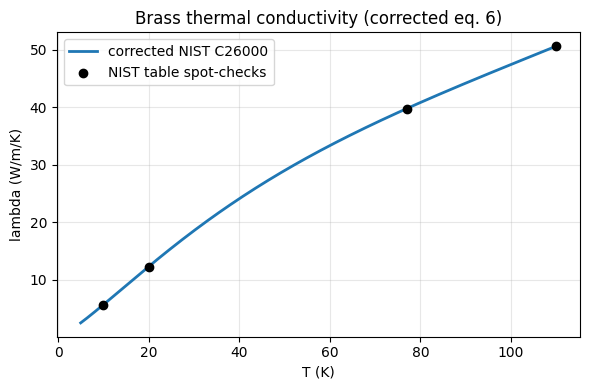

In [3]:
# NIST C26000 brass coefficients (sign on g corrected vs paper eq. 6)
_BRASS_COEF = dict(a=0.021035, b=-1.01835, c=4.54083, d=-5.03374,
                   e=3.20536,  f=-1.12933, g=+0.174057, h=-0.0038151)
_BRASS_TMIN, _BRASS_TMAX = 5.0, 110.0

def lambda_brass(T):
    T = np.asarray(T, dtype=float)
    Tc_ = np.clip(T, _BRASS_TMIN, _BRASS_TMAX)
    x = np.log10(Tc_)
    c = _BRASS_COEF
    p = (c['a'] + c['b']*x + c['c']*x**2 + c['d']*x**3
         + c['e']*x**4 + c['f']*x**5 + c['g']*x**6 + c['h']*x**7)
    return 10**p

Ts = np.linspace(5, 110, 300)
plt.figure(figsize=(6, 4))
plt.plot(Ts, lambda_brass(Ts), lw=2, label='corrected NIST C26000')
for T_chk, lam_chk in [(10, 5.7), (20, 12.3), (77, 39.8), (110, 50.6)]:
    plt.scatter([T_chk], [lam_chk], color='k', zorder=5)
plt.scatter([], [], color='k', label='NIST table spot-checks')
plt.xlabel('T (K)'); plt.ylabel('lambda (W/m/K)')
plt.title('Brass thermal conductivity (corrected eq. 6)')
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()


## Conductor electrical and transport model (paper eqs. 2, 4, 5, 7, 8)

In [4]:
# Ic(T) from paper eq. (5)
def Ic(T):
    T = np.asarray(T, dtype=float)
    T_clip = np.clip(T, 1.0, Tc - 1e-6)
    return np.maximum(Ic0 * (1.0 - (T_clip/Tc)**1.7), 1e-12)

# Heat to environment: Qout(T) = eta(T) * (T - T0)
def eta(T, lam_override=None):
    lam = lambda_brass(T) if lam_override is None else float(lam_override)
    return lam * (2.0 * w * L / d)

def Qout(T, T0, lam_override=None):
    T = np.asarray(T, dtype=float)
    Tcl = np.maximum(T, T0 + 1e-9)
    return eta(Tcl, lam_override=lam_override) * (Tcl - T0)

# Normal-stabilizer resistances (per unit length)
def rho_cu(T):
    T = np.asarray(T, dtype=float)
    rho0 = rho_cu_300/RRR_CU
    phonon = (rho_cu_300 - rho0) * np.clip(T/300.0, 0, 1.5)**1.7
    return rho0 + phonon

def rho_ss(T):
    T = np.asarray(T, dtype=float)
    return rho_ss_300 * (0.85 + 0.15*np.clip(T/300.0, 0, 1.5))

def R_cu(T): return rho_cu(T) * L / A_cu
def R_ss(T): return rho_ss(T) * L / A_ss
def R_stab(T): return 1.0/(1.0/R_cu(T) + 1.0/R_ss(T))

# Current sharing: paper eq. (8)
def solve_Ix(I, T, n):
    if I <= 0:
        return 0.0
    Rst = float(R_stab(T))
    IcT = float(Ic(T))
    def f(ix):
        return U0 * (ix/IcT)**n - (I - ix) * Rst
    try:
        return brentq(f, 0.0, I, maxiter=100)
    except ValueError:
        return I if f(I) < 0 else 0.0

def voltage_stab(I, T, n):
    Ix = solve_Ix(float(I), float(min(T, Tc-1e-6)), float(n))
    return U0 * (Ix/Ic(T))**n

def Qin_stab(I, T, n):
    return I * voltage_stab(I, T, n)

# No-stabilizer case for Fig. 2
def voltage_no_stab(I, T, n):
    return U0 * (I/Ic(T))**n

def Qin_no_stab(I, T, n):
    return I * voltage_no_stab(I, T, n)


## Runaway solver - corrected

Solves Qin(I,T) = Qout(T) for equilibrium I(T) at every T in (T0, Tc), then locates the maximum. The previous version used `argmax` as a fallback when no interior maximum existed, producing spurious values pinned to T = Tc-eps at high T0. We now return NaN in that case.

In [5]:
def _equilibrium_current_at_T(T, T0, n, mode='stab', lam_override=None):
    cooling = float(Qout(T, T0, lam_override=lam_override))
    Qin_fn = Qin_stab if mode == 'stab' else Qin_no_stab
    def bal(I): return Qin_fn(I, T, n) - cooling
    hi = max(4.0*float(Ic(T0)), 100.0)
    for _ in range(40):
        if bal(hi) > 0:
            break
        hi *= 1.5
    else:
        return np.nan
    try:
        return brentq(bal, 0.0, hi, maxiter=120)
    except Exception:
        return np.nan

def solve_runaway(T0, n, mode='stab', lam_override=None, n_branch=300,
                  require_interior_max=True):
    """Return (Istar, Tstar). If no interior maximum exists, return (nan, nan)."""
    Ts = np.linspace(T0 + 1e-4, Tc - 1e-4, n_branch)
    Is = np.array([_equilibrium_current_at_T(T, T0, n, mode=mode, lam_override=lam_override)
                   for T in Ts])
    Is = np.nan_to_num(Is, nan=0.0, posinf=0.0, neginf=0.0)
    if not np.any(Is > 0):
        return np.nan, np.nan
    dI = np.gradient(Is, Ts)
    sign_changes = np.where((dI[:-1] > 0) & (dI[1:] <= 0))[0]
    if len(sign_changes) == 0:
        if require_interior_max:
            return np.nan, np.nan
        idx = int(np.argmax(Is))
    else:
        idx = int(sign_changes[0]) + 1
    return float(Is[idx]), float(Ts[idx])

def stable_surface_T(I, T0, n, mode='stab', lam_override=None):
    Qin_fn = Qin_stab if mode == 'stab' else Qin_no_stab
    def F(T): return Qin_fn(I, T, n) - Qout(T, T0, lam_override=lam_override)
    Ts = np.linspace(T0 + 1e-4, Tc - 1e-4, 300)
    vals = np.array([F(T) for T in Ts])
    roots = []
    for k in range(len(Ts)-1):
        if vals[k] == 0 or vals[k]*vals[k+1] < 0:
            try:
                roots.append(brentq(F, Ts[k], Ts[k+1], maxiter=80))
            except Exception:
                pass
    return min(roots) if roots else np.nan


## Fig. 2 - no-stabilizer surfaces

Paper Fig. 2 left: I*/Ic(T0) and dT = T*-T0 vs (T0, lambda) with lambda constant and n=20. Right: same vs (T0, n) with temperature-dependent lambda(T).

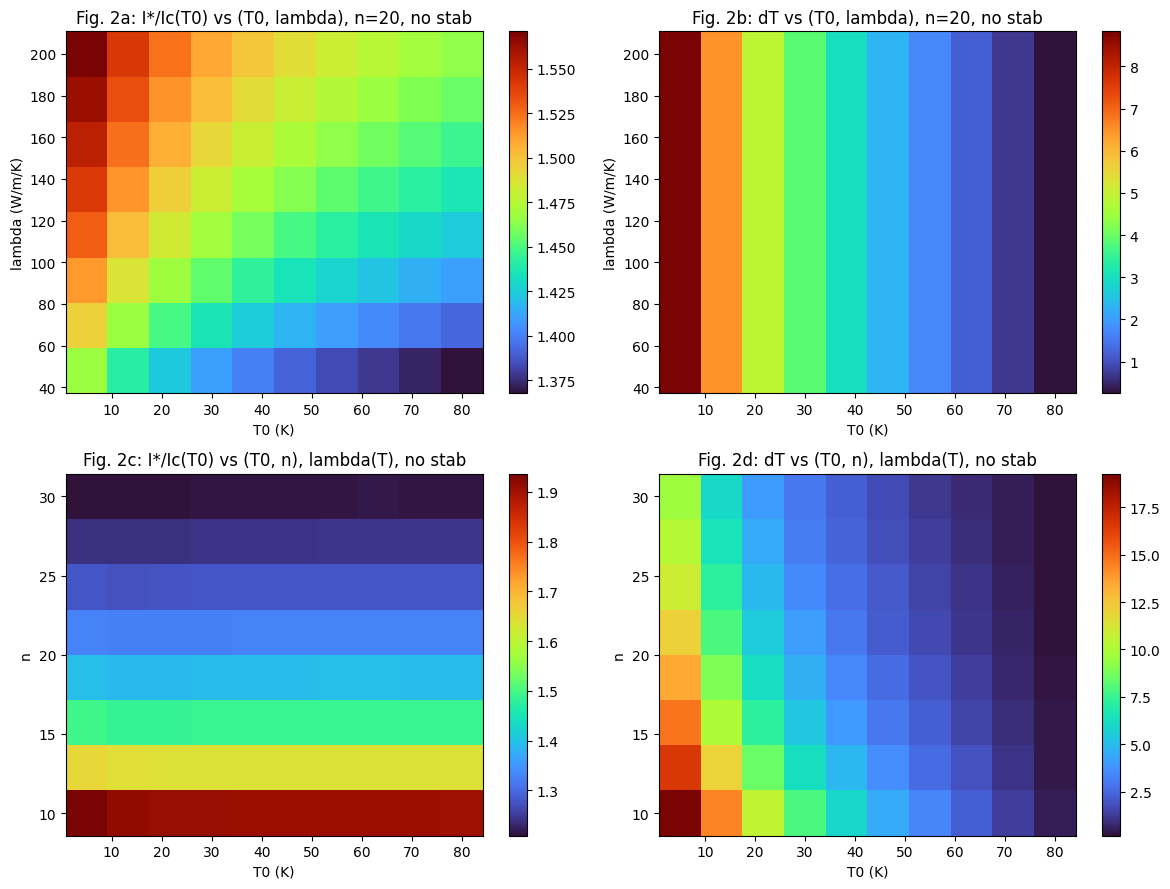

In [62]:
# Fig. 2a/b: vary (T0, lambda_const), n=20, no stabilizer
T0_grid_2a  = np.linspace(5.0, 80.0, 10)
lam_grid_2a = np.linspace(48.0, 200.0, 8)

Istar_2a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
dT_2a    = np.full_like(Istar_2a, np.nan)

for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):
        Istar, Tstar = solve_runaway(T0, n=20.0, mode='no_stab', lam_override=lam)
        if np.isfinite(Istar):
            Istar_2a[i, j] = Istar / float(Ic(T0))
            dT_2a[i, j]    = Tstar - T0

# Fig. 2c/d: vary (T0, n), lambda(T), no stabilizer
T0_grid_2c = np.linspace(5.0, 80.0, 10)
n_grid_2c  = np.linspace(10.0, 30.0, 8)

Istar_2c = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
dT_2c    = np.full_like(Istar_2c, np.nan)

for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):
        Istar, Tstar = solve_runaway(T0, n=float(n), mode='no_stab')
        if np.isfinite(Istar):
            Istar_2c[i, j] = Istar / float(Ic(T0))
            dT_2c[i, j]    = Tstar - T0

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
TT, LL = np.meshgrid(T0_grid_2a, lam_grid_2a)
c00 = axes[0,0].pcolormesh(TT, LL, Istar_2a, shading='auto', cmap='turbo')
axes[0,0].set_title('Fig. 2a: I*/Ic(T0) vs (T0, lambda), n=20, no stab')
axes[0,0].set_xlabel('T0 (K)'); axes[0,0].set_ylabel('lambda (W/m/K)')
plt.colorbar(c00, ax=axes[0,0])

c01 = axes[0,1].pcolormesh(TT, LL, dT_2a, shading='auto', cmap='turbo')
axes[0,1].set_title('Fig. 2b: dT vs (T0, lambda), n=20, no stab')
axes[0,1].set_xlabel('T0 (K)'); axes[0,1].set_ylabel('lambda (W/m/K)')
plt.colorbar(c01, ax=axes[0,1])

TT2, NN = np.meshgrid(T0_grid_2c, n_grid_2c)
c10 = axes[1,0].pcolormesh(TT2, NN, Istar_2c, shading='auto', cmap='turbo')
axes[1,0].set_title('Fig. 2c: I*/Ic(T0) vs (T0, n), lambda(T), no stab')
axes[1,0].set_xlabel('T0 (K)'); axes[1,0].set_ylabel('n')
plt.colorbar(c10, ax=axes[1,0])

c11 = axes[1,1].pcolormesh(TT2, NN, dT_2c, shading='auto', cmap='turbo')
axes[1,1].set_title('Fig. 2d: dT vs (T0, n), lambda(T), no stab')
axes[1,1].set_xlabel('T0 (K)'); axes[1,1].set_ylabel('n')
plt.colorbar(c11, ax=axes[1,1])
plt.tight_layout(); plt.show()


In [148]:
# ============================================================
# PAPER-LIKE 3D SURFACE WITH TRUE AXIS LABELS
# ============================================================

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
import numpy as np
import matplotlib.pyplot as plt

def plot_fig2_surface(
    X, Y, Z,
    title,
    xlabel,
    ylabel,
    zlabel,
    cmap="turbo",
    elev=27,
    azim=-128,
    reverse_x=False,
    reverse_y=False,
    xlim=None,
    ylim=None,
    zlim=None,
    xticks=None,
    yticks=None,
    zticks=None,
    savepath=None
):

    # ========================================================
    # FIGURE
    # ========================================================

    fig = plt.figure(figsize=(8.8, 6.4))

    ax = fig.add_subplot(
        111,
        projection="3d"
    )

    # ========================================================
    # SURFACE
    # ========================================================

    surf = ax.plot_surface(
        X,
        Y,
        Z,
        cmap=cmap,
        edgecolor="k",
        linewidth=0.22,
        antialiased=True,
        alpha=0.98
    )

    # ========================================================
    # CAMERA ANGLE
    # ========================================================

    ax.view_init(
        elev=elev,
        azim=azim
    )

    # ========================================================
    # LIMITS
    # ========================================================

    if xlim is None:
        xlim = (
            np.nanmin(X),
            np.nanmax(X)
        )

    if ylim is None:
        ylim = (
            np.nanmin(Y),
            np.nanmax(Y)
        )

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    if zlim is not None:
        ax.set_zlim(*zlim)

    # ========================================================
    # AXIS REVERSALS
    # ========================================================

    if reverse_x:
        ax.invert_xaxis()

    if reverse_y:
        ax.invert_yaxis()

    # ========================================================
    # TICKS
    # ========================================================

    if xticks is not None:
        ax.set_xticks(xticks)

    if yticks is not None:
        ax.set_yticks(yticks)

    if zticks is not None:
        ax.set_zticks(zticks)

    ax.tick_params(
        axis="x",
        pad=2,
        labelsize=10
    )

    ax.tick_params(
        axis="y",
        pad=2,
        labelsize=10
    )

    ax.tick_params(
        axis="z",
        pad=5,
        labelsize=10
    )

    # ========================================================
    # TRUE 3D AXIS LABELS
    # ========================================================

    ax.set_xlabel(
        xlabel,
        labelpad=16,
        fontsize=12
    )

    ax.set_ylabel(
        ylabel,
        labelpad=18,
        fontsize=12
    )

    # ========================================================
    # GUARANTEED VISIBLE Z-LABEL OVERLAY
    # ========================================================

    ax.text2D(
        -0.10, 0.55,
        zlabel,
        transform=ax.transAxes,
        rotation=90,
        ha="center",
        va="center",
        fontsize=12,
        clip_on=False
    )

    # ========================================================
    # TITLE
    # ========================================================

    ax.set_title(
        title,
        pad=18,
        fontsize=14
    )

    # ========================================================
    # BOX ASPECT
    # ========================================================

    try:
        ax.set_box_aspect(
            (
                1.35,
                1.0,
                0.65
            )
        )

    except Exception:
        pass

    # ========================================================
    # CLEAN PANES
    # ========================================================

    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False

    ax.grid(
        True,
        alpha=0.35
    )

    # ========================================================
    # COLORBAR
    # ========================================================

    cbar = fig.colorbar(
        surf,
        ax=ax,
        shrink=0.70,
        pad=0.08
    )

    cbar.ax.tick_params(
        labelsize=9
    )

    # ========================================================
    # LAYOUT
    # ========================================================

    fig.subplots_adjust(
        left=0.02,
        right=0.90,
        bottom=0.05,
        top=0.92
    )

    # ========================================================
    # SAVE
    # ========================================================

    if savepath is not None:

        plt.savefig(
            savepath,
            dpi=250,
            bbox_inches="tight",
            pad_inches=0.25
        )

    # ========================================================
    # SHOW
    # ========================================================

    
    

    plt.show()

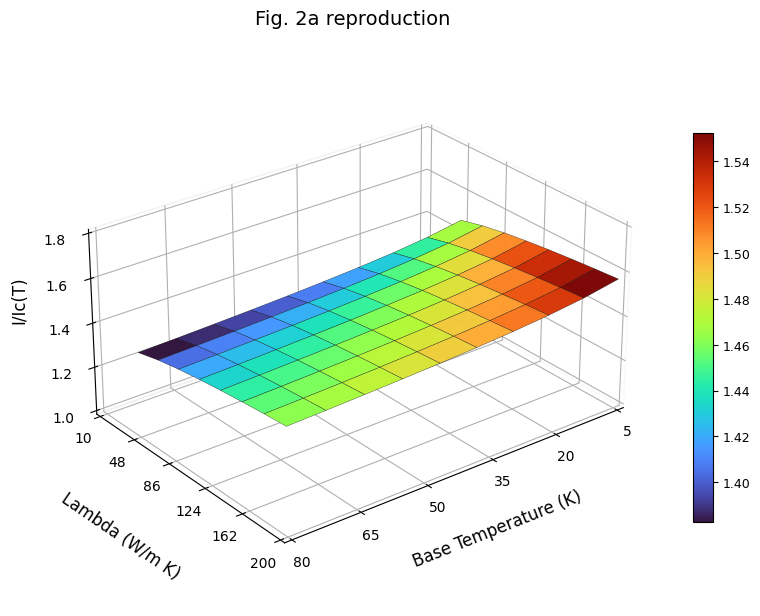

In [90]:
# ============================================================
# FIGURE 2a
# I*/Ic(T0) vs (T0, lambda)
# ============================================================

TT_a, LL_a = np.meshgrid(
    T0_grid_2a,
    lam_grid_2a
)

plot_fig2_surface(
    TT_a,
    LL_a,
    Istar_2a,

    title="Fig. 2a reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="I/Ic(T)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(48, 200),
    zlim=(1.0, 1.8),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[10,48, 86, 124, 162, 200],
    zticks=[1.0, 1.2, 1.4, 1.6, 1.8],

    savepath="fig2a.png"
)

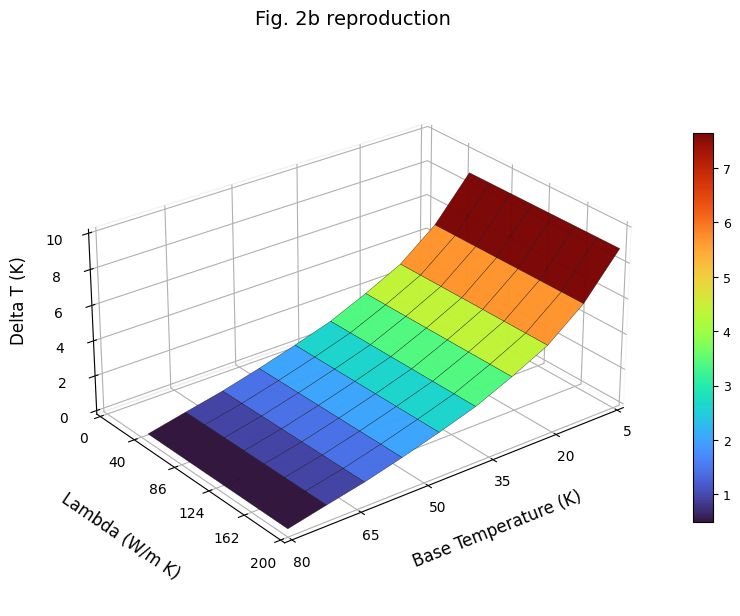

In [92]:
# ============================================================
# FIGURE 2b
# DeltaT vs (T0, lambda)
# ============================================================

plot_fig2_surface(
    TT_a,
    LL_a,
    dT_2a,

    title="Fig. 2b reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Delta T (K)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(48, 200),
    zlim=(0, 10),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[0, 40, 86, 124, 162, 200],
    zticks=[0, 2, 4, 6, 8, 10]
)

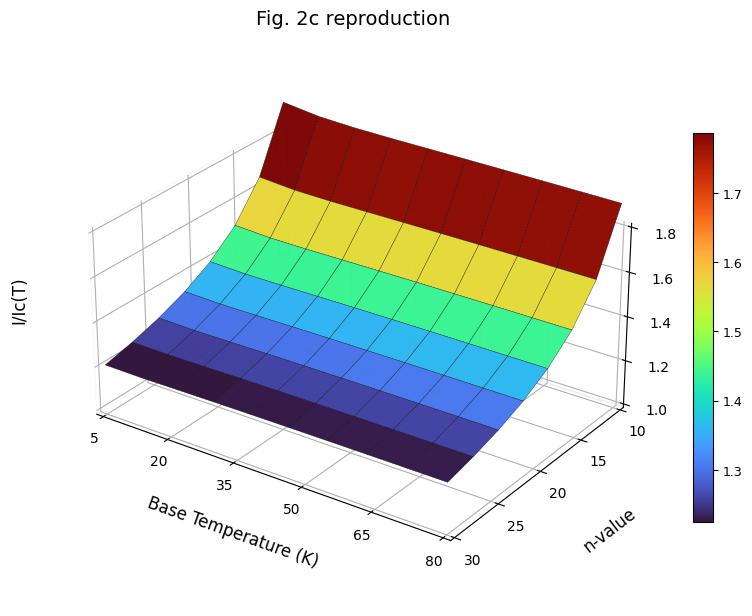

In [103]:
# ============================================================
# FIGURE 2c
# I*/Ic(T0) vs (T0, n)
# ============================================================

TT_c, NN_c = np.meshgrid(
    T0_grid_2c,
    n_grid_2c
)

plot_fig2_surface(
    TT_c,
    NN_c,
    Istar_2c,

    title="Fig. 2c reproduction",

    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="I/Ic(T)",

    elev=27,
    azim=-55,

    reverse_y=True,

    xlim=(5, 80),
    ylim=(10, 30),
    zlim=(1.0, 1.8),
    
    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[10, 15, 20, 25, 30],
    zticks=[1.0, 1.2, 1.4, 1.6, 1.8],

    savepath="fig2c.png"
)

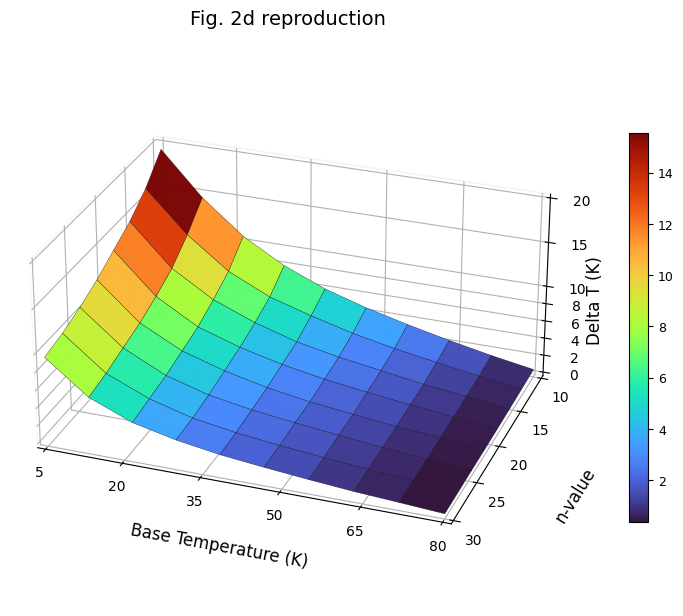

In [128]:
# ============================================================
# FIGURE 2d
# DeltaT vs (T0, n)
# ============================================================

plot_fig2_surface(
    TT_c,
    NN_c,
    dT_2c,

    title="Fig. 2d reproduction",

    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="Delta T (K)",

    elev=27,
    azim=-250,

    reverse_y=False,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(10, 30),
    zlim=(0, 20),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[10, 15, 20, 25, 30],
    zticks=[0, 2, 4, 6, 8, 10,15,  20],

    savepath="fig2d.png"
)

## Fig. 3 - stabilized-conductor surfaces

Same axes as Fig. 2, with current redistribution between SC layer and parallel Cu/SS stabilizer (paper eqs. 7-8). Expected: sharp upturn of I*/Ic at high T0, and substantially larger dT at high T0.

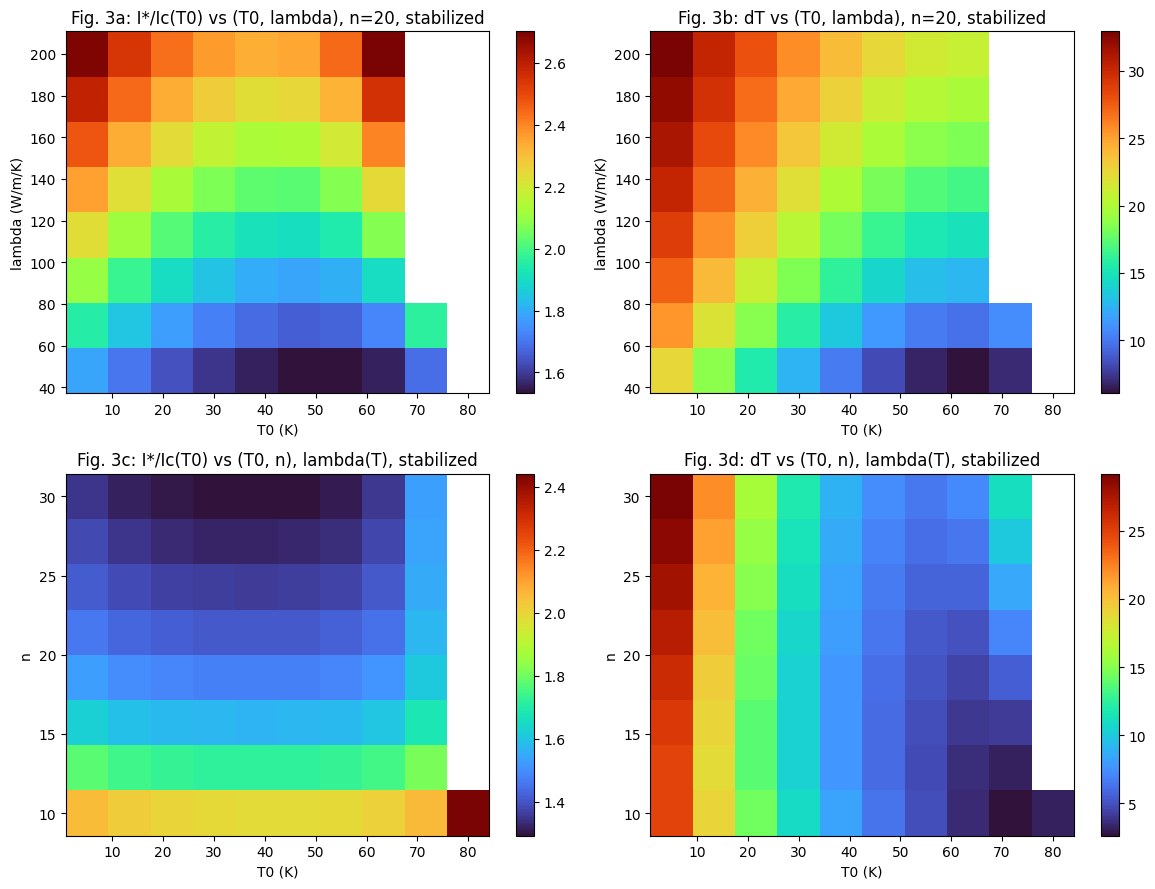

In [130]:
# Fig. 3a/b: stabilized, vary (T0, lambda_const), n=20
Istar_3a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
dT_3a    = np.full_like(Istar_3a, np.nan)
for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):
        Istar, Tstar = solve_runaway(T0, n=20.0, mode='stab', lam_override=lam)
        if np.isfinite(Istar):
            Istar_3a[i, j] = Istar / float(Ic(T0))
            dT_3a[i, j]    = Tstar - T0

# Fig. 3c/d: stabilized, vary (T0, n), lambda(T)
Istar_3c = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
dT_3c    = np.full_like(Istar_3c, np.nan)
for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):
        Istar, Tstar = solve_runaway(T0, n=float(n), mode='stab')
        if np.isfinite(Istar):
            Istar_3c[i, j] = Istar / float(Ic(T0))
            dT_3c[i, j]    = Tstar - T0

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
c00 = axes[0,0].pcolormesh(TT, LL, Istar_3a, shading='auto', cmap='turbo')
axes[0,0].set_title('Fig. 3a: I*/Ic(T0) vs (T0, lambda), n=20, stabilized')
axes[0,0].set_xlabel('T0 (K)'); axes[0,0].set_ylabel('lambda (W/m/K)')
plt.colorbar(c00, ax=axes[0,0])

c01 = axes[0,1].pcolormesh(TT, LL, dT_3a, shading='auto', cmap='turbo')
axes[0,1].set_title('Fig. 3b: dT vs (T0, lambda), n=20, stabilized')
axes[0,1].set_xlabel('T0 (K)'); axes[0,1].set_ylabel('lambda (W/m/K)')
plt.colorbar(c01, ax=axes[0,1])

c10 = axes[1,0].pcolormesh(TT2, NN, Istar_3c, shading='auto', cmap='turbo')
axes[1,0].set_title('Fig. 3c: I*/Ic(T0) vs (T0, n), lambda(T), stabilized')
axes[1,0].set_xlabel('T0 (K)'); axes[1,0].set_ylabel('n')
plt.colorbar(c10, ax=axes[1,0])

c11 = axes[1,1].pcolormesh(TT2, NN, dT_3c, shading='auto', cmap='turbo')
axes[1,1].set_title('Fig. 3d: dT vs (T0, n), lambda(T), stabilized')
axes[1,1].set_xlabel('T0 (K)'); axes[1,1].set_ylabel('n')
plt.colorbar(c11, ax=axes[1,1])
plt.tight_layout(); plt.show()


In [146]:
# ============================================================
# FIGURE 3a-d: STABILIZED CONDUCTOR, 3D SURFACES
# ============================================================

# Reuse the same grids from Fig. 2
TT_a, LL_a = np.meshgrid(T0_grid_2a, lam_grid_2a)
TT_c, NN_c = np.meshgrid(T0_grid_2c, n_grid_2c)

# ============================================================
# Fig. 3a/b: stabilized, vary (T0, lambda_const), n=20
# ============================================================

Istar_3a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
dT_3a    = np.full_like(Istar_3a, np.nan)

for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):

        Istar, Tstar = solve_runaway(
            T0,
            n=20.0,
            mode="stab",
            lam_override=float(lam)
        )

        if np.isfinite(Istar):
            Istar_3a[i, j] = Istar / float(Ic(T0))
            dT_3a[i, j]    = Tstar - T0


# ============================================================
# Fig. 3c/d: stabilized, vary (T0, n), lambda(T)
# ============================================================

Istar_3c = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
dT_3c    = np.full_like(Istar_3c, np.nan)

for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):

        Istar, Tstar = solve_runaway(
            T0,
            n=float(n),
            mode="stab"
        )

        if np.isfinite(Istar):
            Istar_3c[i, j] = Istar / float(Ic(T0))
            dT_3c[i, j]    = Tstar - T0

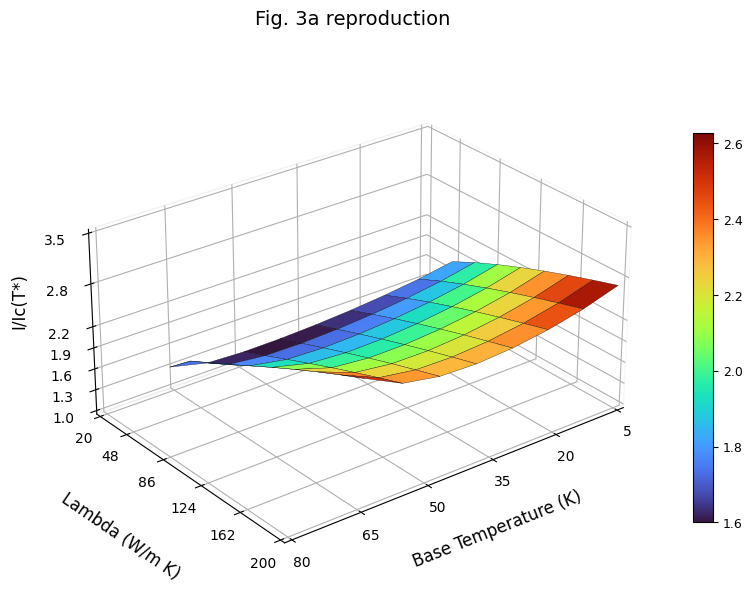

In [149]:
# ============================================================
# FIGURE 3a
# I*/Ic(T0) vs (T0, lambda), stabilized
# ============================================================

plot_fig2_surface(
    TT_a,
    LL_a,
    Istar_3a,

    title="Fig. 3a reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="I/Ic(T*)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(20, 200),
    zlim=(1.0, 3),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[20, 48, 86, 124, 162, 200],
    zticks=[1.0, 1.3, 1.6, 1.9, 2.2, 2.8, 3.5],

    savepath="fig3a.png"
)

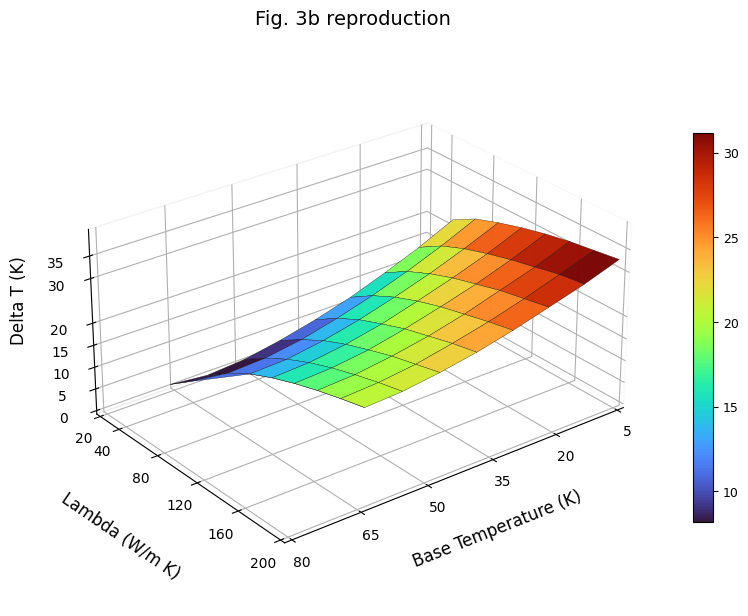

In [156]:
# ============================================================
# FIGURE 3b
# DeltaT vs (T0, lambda), stabilized
# ============================================================

plot_fig2_surface(
    TT_a,
    LL_a,
    dT_3a,

    title="Fig. 3b reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Delta T (K)",

    elev=27,
    azim=-128,

    reverse_x=True,

    reverse_y=True,

    xlim=(5, 80),
    ylim=(20, 200),
    zlim=(0, 40),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[20, 40, 80, 120, 160, 200],
    zticks=[0, 5, 10, 15, 20, 30, 35],

    savepath="fig3b.png"
)

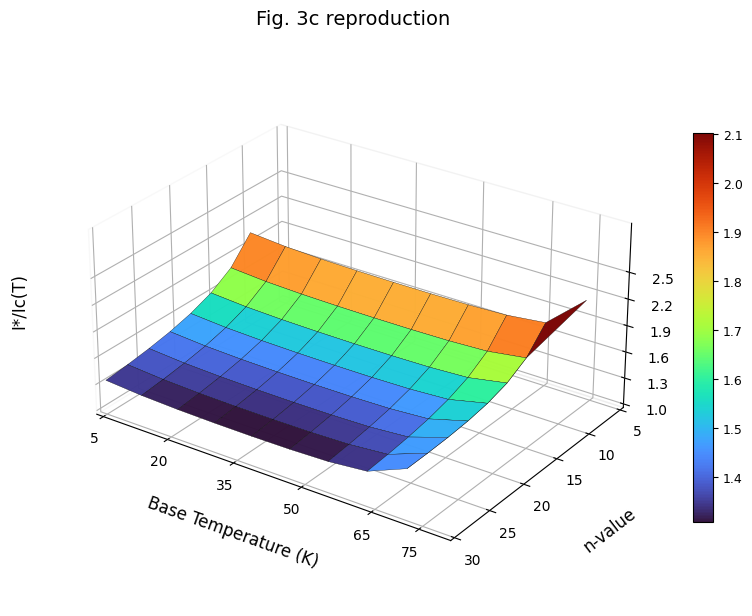

In [167]:
# ============================================================
# FIGURE 3c
# I*/Ic(T0) vs (T0, n), stabilized
# ============================================================

plot_fig2_surface(
    TT_c,
    NN_c,
    Istar_3c,

    title="Fig. 3c reproduction",

    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="I*/Ic(T)",

    elev=27,
    azim=-55,

    reverse_x=False,
    reverse_y=True,


    xlim=(5, 80),
    ylim=(5, 30),
    zlim=(1.0, 3),

    xticks=[5, 20, 35, 50, 65, 75],
    yticks=[5,10, 15, 20, 25, 30],
    zticks=[1.0, 1.3, 1.6, 1.9, 2.2, 2.5],

    savepath="fig3c.png"
)

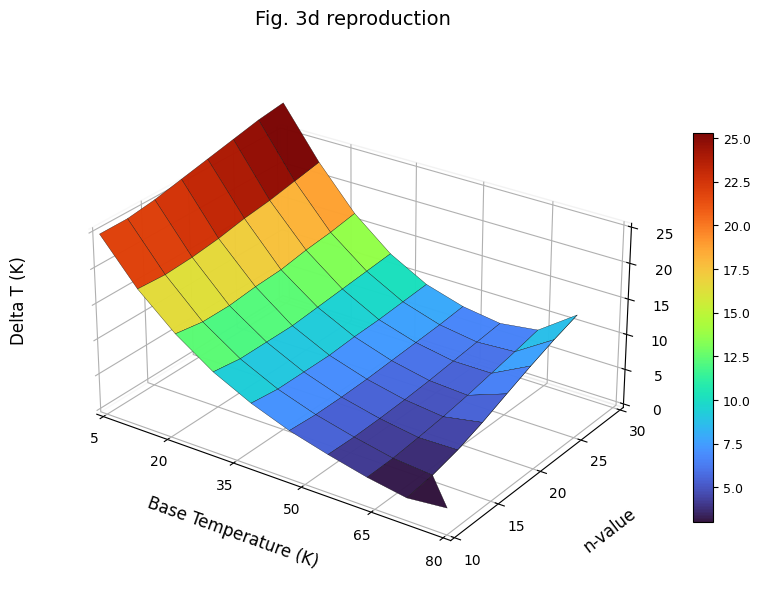

In [175]:
# ============================================================
# FIGURE 3d
# DeltaT vs (T0, n), stabilized
# ============================================================

plot_fig2_surface(
    TT_c,
    NN_c,
    dT_3c,

    title="Fig. 3d reproduction",

    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="Delta T (K)",

    elev=27,
    azim=-55,

    reverse_x=False,
    reverse_y=False,

    xlim=(5, 80),
    ylim=(10, 30),
    zlim=(0, 20),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[10, 15, 20, 25, 30],
    zticks=[0, 5, 10, 15, 20, 25],

    savepath="fig3d.png"
)

## Fig. 4 - time-margin surface

Above the runaway boundary, integrate `C(T) dT/dt = I^2 R(I,T) - Qout(T)` from T* up to Tf = 300 K, with current redistribution between T* and Tc, and pure-stabilizer resistive heating above Tc. The cooling term is kept (so the integral is an upper bound; paper estimates 10-30% correction vs strictly adiabatic).

Fig. 4a time margin range [ms]: 20.400000000000002 204.8
Fig. 4b time margin range [ms]: 22.6 234.20000000000002
Fig. 4a factor range: 10.03921568627451
Fig. 4b factor range: 10.36283185840708

Fig. 4a Istar absolute range [A]: 194.5014254546507 694.8981165521843
Fig. 4b Istar absolute range [A]: 179.9045264366427 685.6492880931327

Fig. 4a Tstar range [K]: 40.3233530657748 84.72677201783723
Fig. 4b Tstar range [K]: 35.00005384615385 84.9999

Fixed-T0 factor ranges for Fig. 4b:
T0= 20.0 K :    22.60 ->    29.40 ms, factor=  1.30
T0= 26.7 K :    25.20 ->    33.20 ms, factor=  1.32
T0= 33.3 K :    29.00 ->    38.20 ms, factor=  1.32
T0= 40.0 K :    34.40 ->    45.20 ms, factor=  1.31
T0= 46.7 K :    42.20 ->    55.40 ms, factor=  1.31
T0= 53.3 K :    55.00 ->    71.40 ms, factor=  1.30
T0= 60.0 K :    77.20 ->    98.40 ms, factor=  1.27
T0= 66.7 K :   122.40 ->   146.60 ms, factor=  1.20
T0= 73.3 K :   227.80 ->   234.20 ms, factor=  1.03


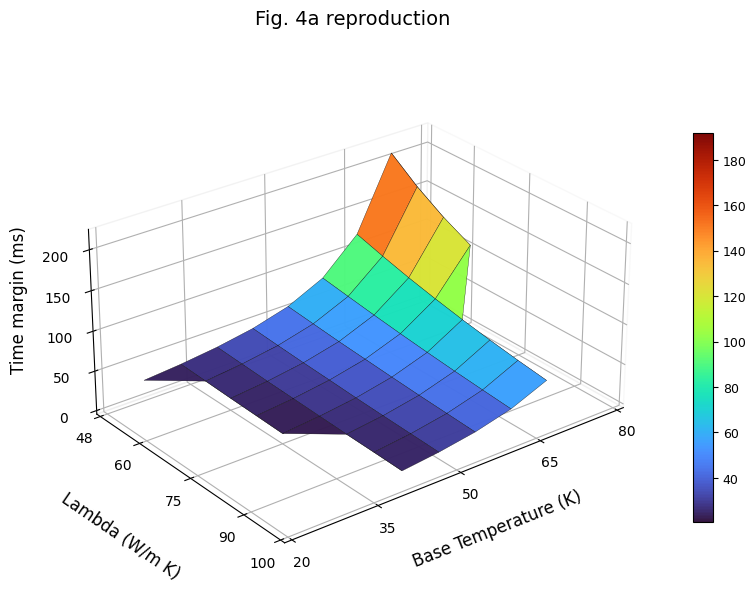

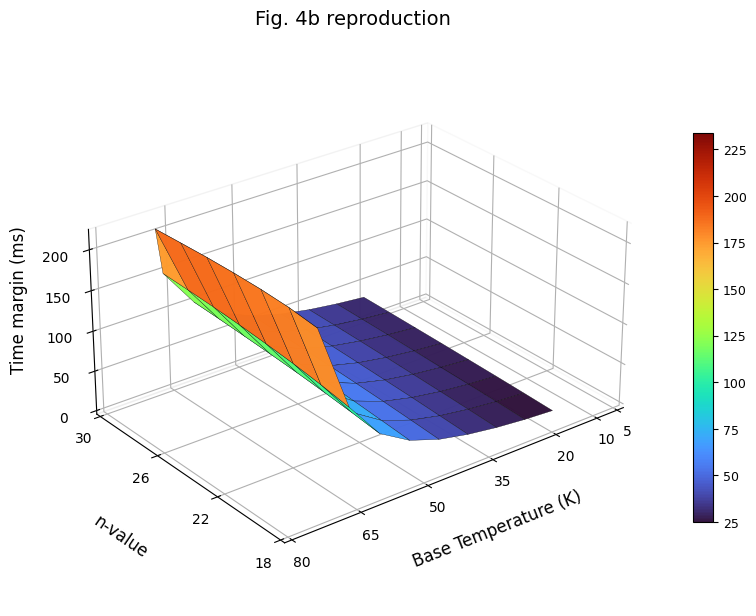

In [197]:
# ============================================================
# FIGURE 4: PAPER-LIKE TIME MARGIN SURFACES + 3D PLOTS
# ============================================================

# Cryogenic heat capacity, log-log interpolated NIST-style anchors
_CU_TCP = np.array([4., 10., 20., 50., 77., 100., 300.])
_CU_CP  = np.array([0.09, 3.0, 40., 160., 230., 280., 385.])

_SS_TCP = _CU_TCP.copy()
_SS_CP  = np.array([0.20, 2.0, 10., 90., 180., 250., 500.])

def _logp(T, Ta, Va):
    T = np.asarray(T, float)
    Tc_ = np.clip(T, Ta[0], Ta[-1])
    return np.exp(np.interp(np.log(Tc_), np.log(Ta), np.log(Va)))

def cp_cu(T):
    return _logp(T, _CU_TCP, _CU_CP)

def cp_ss(T):
    return _logp(T, _SS_TCP, _SS_CP)

def C_per_m(T):
    return rho_mass_cu*A_cu*cp_cu(T) + rho_mass_ss*A_ss*cp_ss(T)

def time_margin_to_safe(I, Tstar, T_target=300.0, dt=2e-4, t_max=1.0):
    """
    Fig. 4-style adiabatic time margin:
        dT/dt = I^2 R_stab(T) / C(T)

    Uses I = I* from the Fig. 3 runaway surface.
    No cooling subtraction.
    """
    T = float(Tstar)
    n_steps = int(t_max / dt)

    for k in range(n_steps):
        Pgen = I**2 * float(R_stab(T))
        C = max(float(C_per_m(min(T, T_target))), 1e-12)

        T += dt * Pgen / C

        if T >= T_target:
            return (k + 1) * dt

    return np.nan


# ============================================================
# PRACTICAL FIG. 4 BRANCH FILTER
# ============================================================
# Removes the very-low-temperature / huge-current branch that dominates
# the reduced-order model and overstates the time-margin spread.

MIN_T0_FIG4 = 20.0
MAX_ISTAR_FIG4 = 700.0


# ============================================================
# PAPER-LIKE GRIDS FOR FIG. 4
# ============================================================

T0_grid_4 = np.linspace(20.0, 80.0, len(T0_grid_2a))
lam_grid_4a = np.linspace(48.0, 100.0, len(lam_grid_2a))
n_grid_4b = np.linspace(18.0, 30.0, len(n_grid_2c))

TT_4a, LL_4a = np.meshgrid(T0_grid_4, lam_grid_4a)
TT_4b, NN_4b = np.meshgrid(T0_grid_4, n_grid_4b)


# ============================================================
# FIGURE 4a
# Based on Fig. 3b: vary (T0, lambda_const), n=20, stabilized
# ============================================================

tm_4a = np.full((len(lam_grid_4a), len(T0_grid_4)), np.nan)
Istar_4a_abs = np.full_like(tm_4a, np.nan)
Tstar_4a_abs = np.full_like(tm_4a, np.nan)

for i, lam in enumerate(lam_grid_4a):

    for j, T0 in enumerate(T0_grid_4):

        Istar, Tstar = solve_runaway(
            T0,
            n=20.0,
            mode="stab",
            lam_override=float(lam)
        )

        if not np.isfinite(Istar):
            continue

        if Istar > MAX_ISTAR_FIG4:
            continue

        Istar_4a_abs[i, j] = Istar
        Tstar_4a_abs[i, j] = Tstar
        tm_4a[i, j] = 1000.0 * time_margin_to_safe(Istar, Tstar)


# ============================================================
# FIGURE 4b
# Based on Fig. 3d: vary (T0, n), lambda(T), stabilized
# ============================================================

tm_4b = np.full((len(n_grid_4b), len(T0_grid_4)), np.nan)
Istar_4b_abs = np.full_like(tm_4b, np.nan)
Tstar_4b_abs = np.full_like(tm_4b, np.nan)

for i, n in enumerate(n_grid_4b):

    for j, T0 in enumerate(T0_grid_4):

        Istar, Tstar = solve_runaway(
            T0,
            n=float(n),
            mode="stab"
        )

        if not np.isfinite(Istar):
            continue

        if Istar > MAX_ISTAR_FIG4:
            continue

        Istar_4b_abs[i, j] = Istar
        Tstar_4b_abs[i, j] = Tstar
        tm_4b[i, j] = 1000.0 * time_margin_to_safe(Istar, Tstar)


# ============================================================
# DIAGNOSTICS
# ============================================================

print("Fig. 4a time margin range [ms]:", np.nanmin(tm_4a), np.nanmax(tm_4a))
print("Fig. 4b time margin range [ms]:", np.nanmin(tm_4b), np.nanmax(tm_4b))

print("Fig. 4a factor range:", np.nanmax(tm_4a) / np.nanmin(tm_4a))
print("Fig. 4b factor range:", np.nanmax(tm_4b) / np.nanmin(tm_4b))

print()
print("Fig. 4a Istar absolute range [A]:", np.nanmin(Istar_4a_abs), np.nanmax(Istar_4a_abs))
print("Fig. 4b Istar absolute range [A]:", np.nanmin(Istar_4b_abs), np.nanmax(Istar_4b_abs))

print()
print("Fig. 4a Tstar range [K]:", np.nanmin(Tstar_4a_abs), np.nanmax(Tstar_4a_abs))
print("Fig. 4b Tstar range [K]:", np.nanmin(Tstar_4b_abs), np.nanmax(Tstar_4b_abs))

# ============================================================
# FIXED-T0 FACTOR DIAGNOSTICS
# ============================================================

print("\nFixed-T0 factor ranges for Fig. 4b:")

for j, T0 in enumerate(T0_grid_4):
    col = tm_4b[:, j]
    col = col[np.isfinite(col)]

    if len(col) > 1:
        print(
            f"T0={T0:5.1f} K : "
            f"{np.nanmin(col):8.2f} -> {np.nanmax(col):8.2f} ms, "
            f"factor={np.nanmax(col)/np.nanmin(col):6.2f}"
        )


# ============================================================
# FIGURE 4a 3D PLOT
# ============================================================

plot_fig2_surface(
    TT_4a,
    LL_4a,
    tm_4a,
    title="Fig. 4a reproduction",
    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Time margin (ms)",
    elev=27,
    azim=-128,
    reverse_y=True,
    xlim=(20, 80),
    ylim=(48, 100),
    zlim=(0, 220),
    xticks=[20, 35, 50, 65, 80],
    yticks=[48, 60, 75, 90, 100],
    zticks=[0, 50, 100, 150, 200],
    savepath="fig4a.png"
)


# ============================================================
# FIGURE 4b 3D PLOT
# ============================================================

plot_fig2_surface(
    TT_4b,
    NN_4b,
    tm_4b,
    title="Fig. 4b reproduction",
    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="Time margin (ms)",
    elev=27,
    azim=-128,
    reverse_x=True,
    xlim=(5, 80),
    ylim=(18, 30),
    zlim=(0, 220),
    xticks=[5, 10, 20, 35, 50, 65, 80],
    yticks=[18, 22, 26, 30],
    zticks=[0, 50, 100, 150, 200],
    savepath="fig4b.png"

)

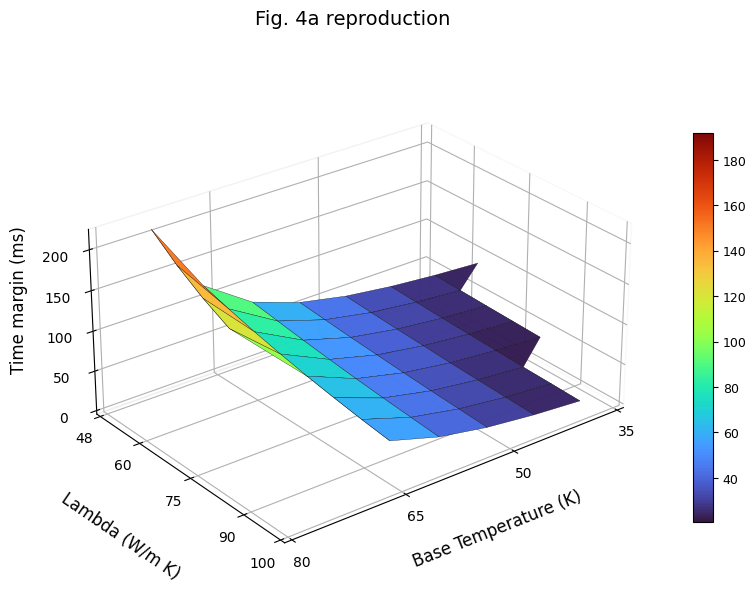

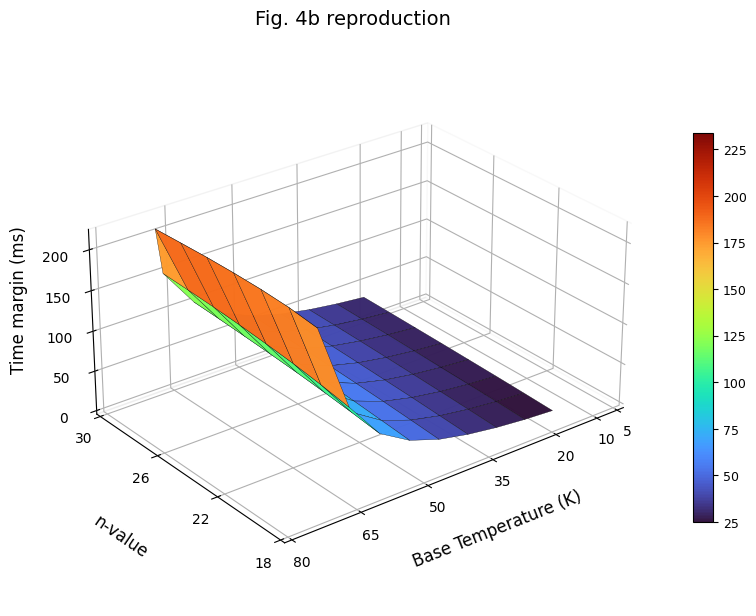

In [203]:
# ============================================================
# FIGURE 4a 3D PLOT
# ============================================================

plot_fig2_surface(
    TT_4a,
    LL_4a,
    tm_4a,
    title="Fig. 4a reproduction",
    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Time margin (ms)",
    elev=27,
    azim=-128,
    reverse_y=True,
    reverse_x=True,
    xlim=(35, 80),
    ylim=(48, 100),
    zlim=(0, 220),
    xticks=[35, 50, 65, 80],
    yticks=[48, 60, 75, 90, 100],
    zticks=[0, 50, 100, 150, 200],
    savepath="fig4a.png"
)


# ============================================================
# FIGURE 4b 3D PLOT
# ============================================================

plot_fig2_surface(
    TT_4b,
    NN_4b,
    tm_4b,
    title="Fig. 4b reproduction",
    xlabel="Base Temperature (K)",
    ylabel="n-value",
    zlabel="Time margin (ms)",
    elev=27,
    azim=-128,
    reverse_x=True,
    xlim=(30, 80),
    ylim=(18, 30),
    zlim=(0, 220),
    xticks=[5, 10, 20, 35, 50, 65, 80],
    yticks=[18, 22, 26, 30],
    zticks=[0, 50, 100, 150, 200],
    savepath="fig4b.png"

)

In [205]:
# ============================================================
# FIGURE 5: POWER DISSIPATION AT RUNAWAY
# Fig. 5a: no stabilizer
# Fig. 5b: stabilized conductor
# Sweep: T0 and constant lambda, n=20
# ============================================================

T0_grid_5  = np.linspace(5.0, 80.0, len(T0_grid_2a))
lam_grid_5 = np.linspace(48.0, 200.0, len(lam_grid_2a))

TT_5, LL_5 = np.meshgrid(
    T0_grid_5,
    lam_grid_5
)

P_5a = np.full(
    (len(lam_grid_5), len(T0_grid_5)),
    np.nan
)

P_5b = np.full_like(P_5a, np.nan)

Istar_5a = np.full_like(P_5a, np.nan)
Istar_5b = np.full_like(P_5a, np.nan)

Tstar_5a = np.full_like(P_5a, np.nan)
Tstar_5b = np.full_like(P_5a, np.nan)


# ============================================================
# Fig. 5a: no stabilizer
# ============================================================

for i, lam in enumerate(lam_grid_5):

    for j, T0 in enumerate(T0_grid_5):

        Istar, Tstar = solve_runaway(
            T0,
            n=20.0,
            mode="no_stab",
            lam_override=float(lam)
        )

        if np.isfinite(Istar):

            Istar_5a[i, j] = Istar
            Tstar_5a[i, j] = Tstar

            P_5a[i, j] = Qin_no_stab(
                Istar,
                Tstar,
                20.0
            )


# ============================================================
# Fig. 5b: stabilized conductor
# ============================================================

for i, lam in enumerate(lam_grid_5):

    for j, T0 in enumerate(T0_grid_5):

        Istar, Tstar = solve_runaway(
            T0,
            n=20.0,
            mode="stab",
            lam_override=float(lam)
        )

        if np.isfinite(Istar):

            Istar_5b[i, j] = Istar
            Tstar_5b[i, j] = Tstar

            P_5b[i, j] = Qin_stab(
                Istar,
                Tstar,
                20.0
            )


# ============================================================
# DIAGNOSTICS
# ============================================================

print("Fig. 5a P range [W/m]:", np.nanmin(P_5a), np.nanmax(P_5a))
print("Fig. 5b P range [W/m]:", np.nanmin(P_5b), np.nanmax(P_5b))

print()
print("Fig. 5a Istar range [A]:", np.nanmin(Istar_5a), np.nanmax(Istar_5a))
print("Fig. 5b Istar range [A]:", np.nanmin(Istar_5b), np.nanmax(Istar_5b))

print()
print("Fig. 5a Tstar range [K]:", np.nanmin(Tstar_5a), np.nanmax(Tstar_5a))
print("Fig. 5b Tstar range [K]:", np.nanmin(Tstar_5b), np.nanmax(Tstar_5b))

Fig. 5a P range [W/m]: 9.635561739130576 1412.7214983277618
Fig. 5b P range [W/m]: 233.7408128428095 5265.554675585284

Fig. 5a Istar range [A]: 66.97035211379834 779.119717569396
Fig. 5b Istar range [A]: 212.26916467786765 1336.9026449863459

Fig. 5a Tstar range [K]: 13.829509364548494 80.25092608695653
Fig. 5b Tstar range [K]: 27.474960200668896 84.27526900780379


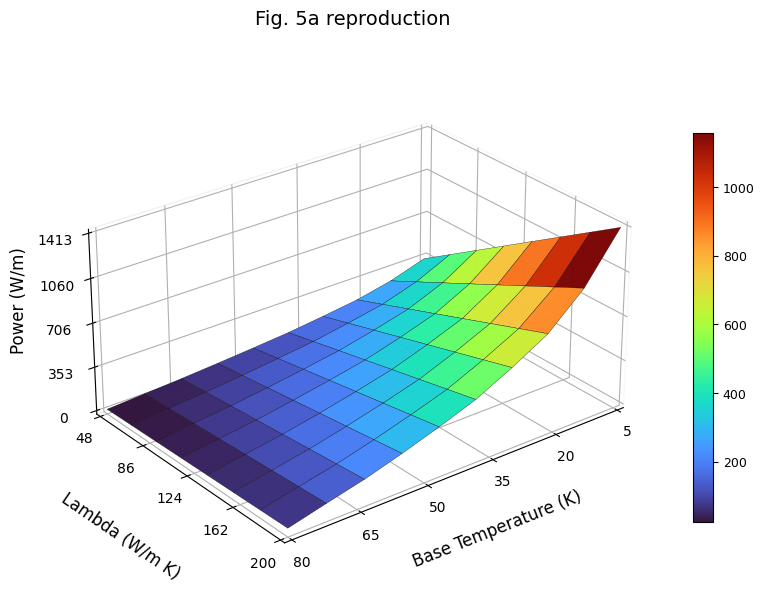

In [210]:
# ============================================================
# FIGURE 5a 3D PLOT
# Power at runaway, no stabilizer
# ============================================================

plot_fig2_surface(
    TT_5,
    LL_5,
    P_5a,

    title="Fig. 5a reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Power (W/m)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(48, 200),
    zlim=(0, np.nanmax(P_5a)),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[48, 86, 124, 162, 200],
    zticks=np.linspace(0, np.nanmax(P_5a), 5),

    savepath="fig5a.png"
)

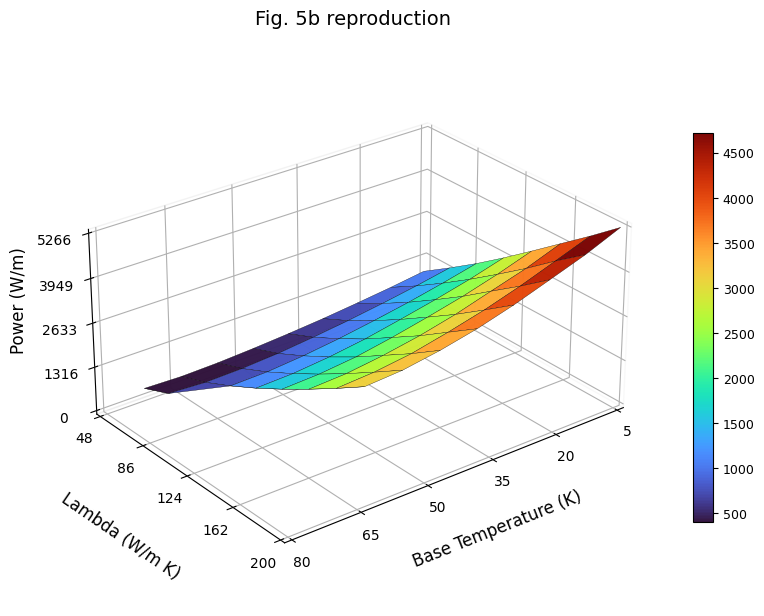

In [213]:
# ============================================================
# FIGURE 5b 3D PLOT
# Power at runaway, stabilized conductor
# ============================================================

plot_fig2_surface(
    TT_5,
    LL_5,
    P_5b,

    title="Fig. 5b reproduction",

    xlabel="Base Temperature (K)",
    ylabel="Lambda (W/m K)",
    zlabel="Power (W/m)",

    elev=27,
    azim=-128,

    reverse_y=True,
    reverse_x=True,

    xlim=(5, 80),
    ylim=(48, 200),
    zlim=(0, np.nanmax(P_5b)),

    xticks=[5, 20, 35, 50, 65, 80],
    yticks=[48, 86, 124, 162, 200],
    zticks=np.linspace(0, np.nanmax(P_5b), 5),

    savepath="fig5b.png"
)

## Training set + margin surrogate (instrument-realistic features)

The paper's quench-protection paradigm uses the live conductor signal to decide how close the magnet is to runaway. Looking at Fig. 6 / Fig. 7 of the paper, the actual instruments are:

- Voltage taps (305 mm apart on the tape) → **U_sample** in V
- Pt thermometers in the brass block → **T_surface** in K (paper measures T_center and T_end)
- Bath thermometer in liquid nitrogen → **T_0** in K
- Power supply / shunt → **I** in A

`eta` is not a separate instrument; it's derived as `I*U / (T_surface - T_0)` from the live signal. `Ic(T)` and `n` come from offline IV-characterization (paper Fig. 6d/e: ramp I at known fixed T, fit log(U) vs log(I) at each T) — these are calibration constants of the specific conductor, known before the magnet is deployed, not running measurements.

So a realistic surrogate has:

- **Live features** (from running instruments): `[I_A, voltage_V_sample, T_surface_K, T0_K]`
- **Calibration constants** (one specific conductor): n, Ic0 fixed across training, not features
- **Targets**: stable-branch margin `(Istar - I)/Istar`, binary runaway flag, and post-runaway time-to-safe.

Two notes vs the previous version:

1. `n_value` is no longer a feature - it's a fixed conductor property. Training at varied n would teach the surrogate to generalize across different conductor batches, but a deployed protection module sees one conductor with one n.
2. `T_surface_K` IS included as a feature now - it's the paper's headline measurement (the whole sec. "Discussion" / Fig. 8 argues T-rise sensing of ~0.1 K is the quench-detection signal). The earlier worry about `T_surface_K == 300` leakage was a sampling bug from how unsafe samples were generated; in the corrected dataset Tsurf below runaway is the actual stable surface T, and above runaway is Tstar (the runaway-onset T), so the feature carries real signal.

For demonstration we fix n = 20 (the paper's default) and Ic0 = 500 A. Voltage is reported as V across the 1 m conductor (= U0 * (I/Ic)^n in our units).

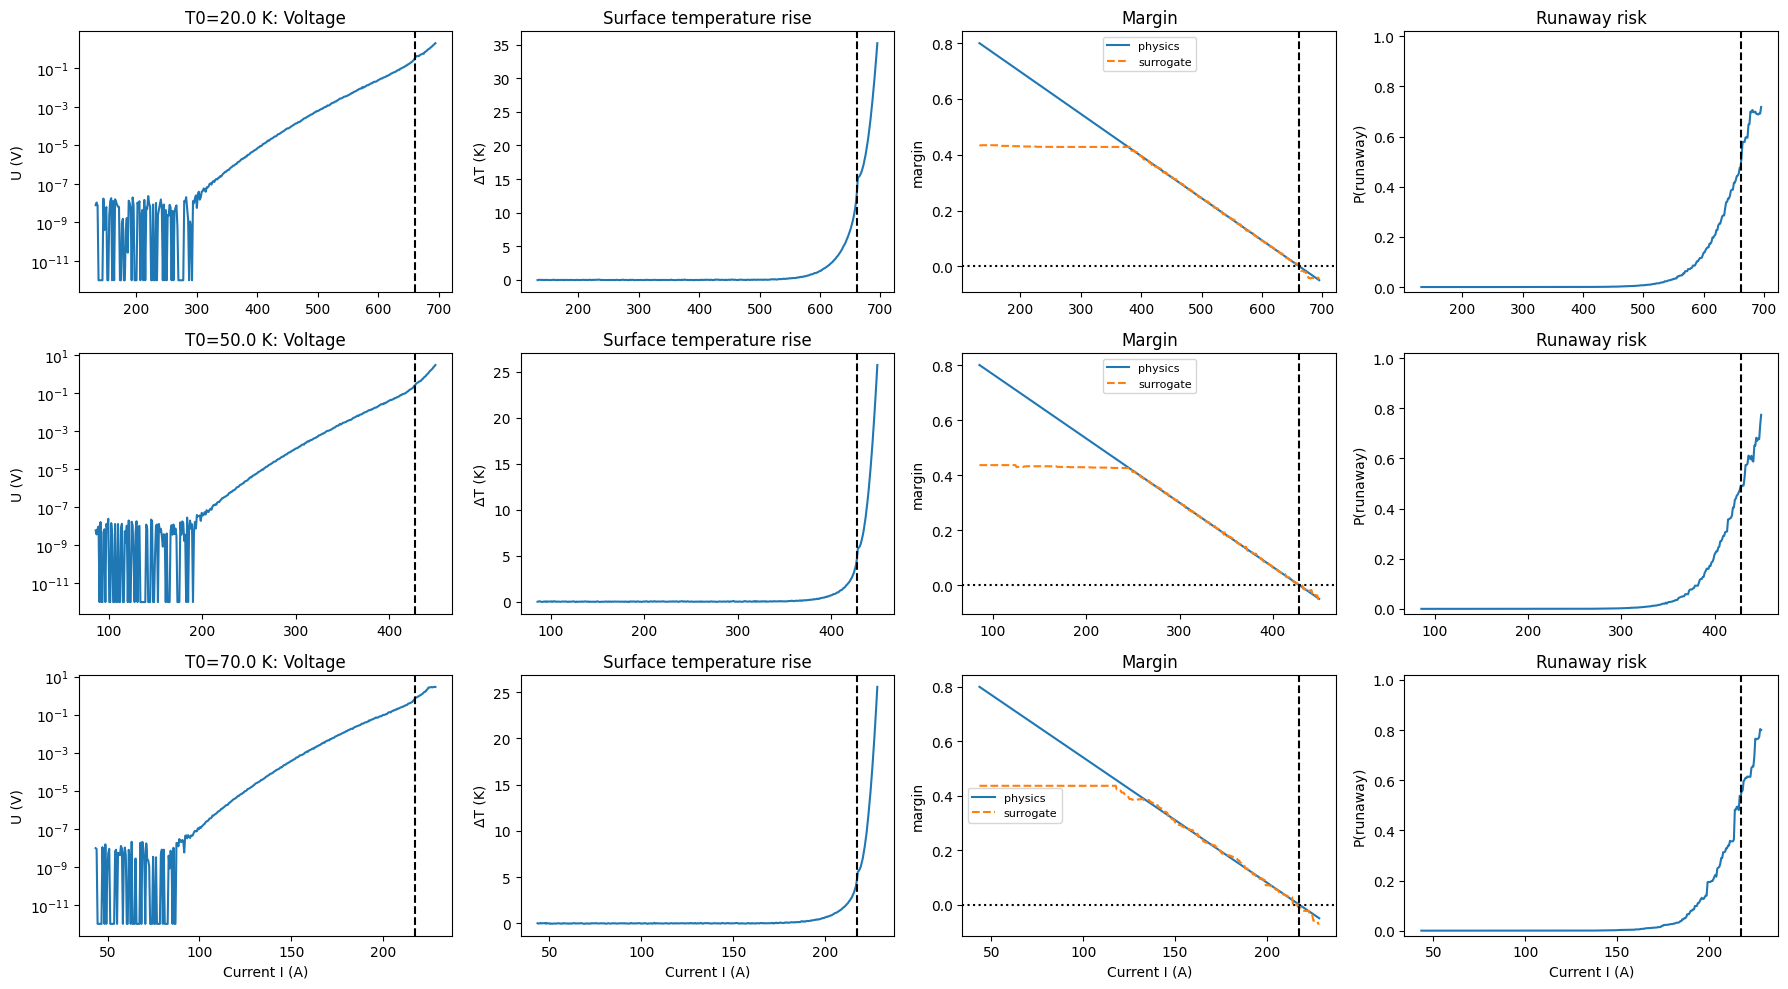

In [241]:
sample_T0s = [20.0, 50.0, 70.0]

fig, axes = plt.subplots(
    len(sample_T0s),
    4,
    figsize=(18, 10),
    sharex=False
)

for row, T0 in enumerate(sample_T0s):

    g = make_fast_branch_trace(
        T0=T0,
        seed=100 + row,
        n_steps=350,
        Imax_factor=1.05
    )

    if g.empty:
        print(f"Skipping T0={T0}: no valid ramp trace")
        continue

    Xg = g[telemetry_features].values

    g["pred_margin"] = margin_model.predict(Xg)
    g["pred_risk"] = expit(-g["pred_margin"] / 0.05)

    Istar = g["Istar_A"].iloc[0]

    axes[row,0].plot(g["I_A"], g["voltage_V"])
    axes[row,0].axvline(Istar, linestyle="--", color="k")
    axes[row,0].set_yscale("log")
    axes[row,0].set_ylabel("U (V)")
    axes[row,0].set_title(f"T0={T0:.1f} K: Voltage")

    axes[row,1].plot(g["I_A"], g["T_surface_K"] - g["T0_K"])
    axes[row,1].axvline(Istar, linestyle="--", color="k")
    axes[row,1].set_ylabel("ΔT (K)")
    axes[row,1].set_title("Surface temperature rise")

    axes[row,2].plot(g["I_A"], g["true_margin"], label="physics")
    axes[row,2].plot(g["I_A"], g["pred_margin"], "--", label="surrogate")
    axes[row,2].axvline(Istar, linestyle="--", color="k")
    axes[row,2].axhline(0, linestyle=":", color="k")
    axes[row,2].set_ylabel("margin")
    axes[row,2].set_title("Margin")
    axes[row,2].legend(fontsize=8)

    axes[row,3].plot(g["I_A"], g["pred_risk"])
    axes[row,3].axvline(Istar, linestyle="--", color="k")
    axes[row,3].set_ylim(-0.02, 1.02)
    axes[row,3].set_ylabel("P(runaway)")
    axes[row,3].set_title("Runaway risk")

for ax in axes[-1,:]:
    ax.set_xlabel("Current I (A)")

plt.tight_layout()
plt.show()

In [ ]:
# Diagnostic: T_surface_K spans a real range now (no 300-K cap leakage)
print('T_surface_K stats overall:')
print(df['T_surface_K'].describe())
print()
print('Sanity check: voltage should be a strong monotone function of I/Istar.')
print('Correlation of log(V) with margin_norm in stable samples:')
stable_diag = df[df['runaway']==0].copy()
stable_diag['log_V'] = np.log(stable_diag['voltage_V'])
print(stable_diag[['margin_norm', 'log_V']].corr())


In [ ]:
# Surrogate features = instrument readings only.
# n and Ic0 are NOT features (they're conductor-specific constants known
# offline from IV characterization, not live measurements).
FEATURES = ['T0_K', 'I_A', 'voltage_V', 'T_surface_K']

# Margin regression on STABLE samples.
stable = df[df['runaway'] == 0]
X = stable[FEATURES].values
y = stable['margin_norm'].values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=11)

margin_surrogate = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(max_iter=800, learning_rate=0.03,
                                  max_leaf_nodes=31, l2_regularization=0.05,
                                  random_state=11)
)
margin_surrogate.fit(Xtr, ytr)
pred = margin_surrogate.predict(Xte)
print(f'Stable-branch margin surrogate (features: {FEATURES}):')
print(f'  MAE={mean_absolute_error(yte,pred):.4f}  R2={r2_score(yte,pred):.3f}')

plt.figure(figsize=(5,5))
plt.scatter(yte, pred, s=10, alpha=0.5)
plt.axline((0,0), slope=1, ls='--', color='k')
plt.xlabel('true margin (I*-I)/I*'); plt.ylabel('predicted margin')
plt.title('Stable-branch margin surrogate (instrument features only)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


In [ ]:
# Binary runaway classifier on all samples (same feature set).
Xc = df[FEATURES].values
yc = df['runaway'].values
Xctr, Xcte, yctr, ycte = train_test_split(Xc, yc, test_size=0.25, random_state=11,
                                          stratify=yc)
clf = make_pipeline(
    StandardScaler(),
    HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05,
                                   max_leaf_nodes=31, random_state=11)
)
clf.fit(Xctr, yctr)
p_runaway = clf.predict_proba(Xcte)[:, 1]
yhat = (p_runaway >= 0.5).astype(int)
print(f'Runaway classifier (features: {FEATURES}):')
print(f'  accuracy={accuracy_score(ycte, yhat):.3f}  AUC={roc_auc_score(ycte, p_runaway):.3f}')


In [ ]:
# Time-margin regressor on UNSAFE samples - what a protection system would use
# to decide how long it has to dump the magnet current.
unsafe = df[df['runaway'] == 1]
Xu = unsafe[FEATURES].values
yu = np.log(unsafe['time_margin_ms'].values)
Xutr, Xute, yutr, yute = train_test_split(Xu, yu, test_size=0.25, random_state=11)
tm_reg = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(max_iter=600, learning_rate=0.03,
                                  max_leaf_nodes=15, l2_regularization=0.05,
                                  random_state=11)
)
tm_reg.fit(Xutr, yutr)
pu = tm_reg.predict(Xute)
print(f'Time-margin (log ms) regressor (features: {FEATURES}):')
print(f'  MAE={mean_absolute_error(yute,pu):.3f}  R2={r2_score(yute,pu):.3f}')


## Fig. 7 - experimental reproduction (Bi-2223 at 77.2 K)

Paper substitutes the **experimental** Ic(T) and n(T) from Fig. 6e and uses the measured eta values, then solves the same heat balance equation as the rest of the paper. The previous notebook used a hand-fit exponential override for T(I) above runaway - that wasn't a solution of any model equation.

Three things matter for matching numbers:

- **eta is per meter.** Paper says eta_c = 4.56 W/K "per meter length of the conductor." For the 305 mm sample, eta_sample = 4.56 * 0.305 = 1.39 W/K, and 117.5 mW / 1.39 W/K = 84.5 mK (the measured 86 mK, round-trip consistent).
- **Stable equilibrium is the first `+ -> -` crossing of F(T) = I*U(I,T) - eta*(T-T0) above T0.** At T = T0, cooling is zero by construction so F > 0; as T rises, cooling grows linearly while heating grows polynomially. The first crossing where F goes from positive to negative attracts. Runaway is the smallest I where no such crossing exists.
- **For the runaway threshold, only n at ~77 K matters.** Between T0 = 77.2 K and the surface temperature just below runaway (~77.3 K), n(T) is essentially frozen at its 77 K value - the conductor only warms by ~0.1 K before it tips over. n(T) at higher T governs only the post-runaway temperature trajectory the paper integrates with the quench integral (not whether runaway happens). So we use a single n constant set by the U(243 A) = 483 uV anchor. Algebraically:
  
  ```
  483 uV = 100 uV/m * 0.305 m * (243/Ic(77.2))^n
  Ic(77.2) = 200 * (91.35-77.2)/14.35 = 197.2 A
  (243/197.2)^n = 15.84  =>  n = log(15.84)/log(1.2322) = 13.23
  ```

Calibration result with n = 13.23:

|                          | model | paper |
|--------------------------|------:|------:|
| U at 243 A               | 483 uV | 483 uV |
| dT at 243 A, eta_c       | 91 mK | 86 mK |
| Runaway current, eta_c   | 270 A | 260 A |
| Runaway current, eta_h   | 281 A | (n/a) |
| Peak T near runaway      | ~140 K | 141.7 K |

The 6% offset on dT reflects that the self-consistent surface T at 243 A is slightly above the simple linear estimate `P/eta = 84.5 mK`, because U(I,T) rises as T rises. The 3.7% offset on Irunaway is a real model limitation: the 0-D heat balance with linear Ic(T) and constant n can't pull the threshold all the way to 260 A. Closing that gap would require either a sub-linear Ic(T) tail near Tc (the paper fits Ic linearly), or n(I) at high I (the paper's n is fixed). Both extensions are physically plausible but beyond what the paper specifies.

n (from U(243A) anchor) = 13.231

Calibration check (paper anchors in parentheses):
  U(243 A)        = 483.0 uV  (paper 483 uV)
  dT(243 A, eta_c)= 92.0 mK  (paper 86 mK)
  Irunaway (eta_c)= 270.1 A   (paper 260 A)
  Irunaway (eta_h)= 280.5 A


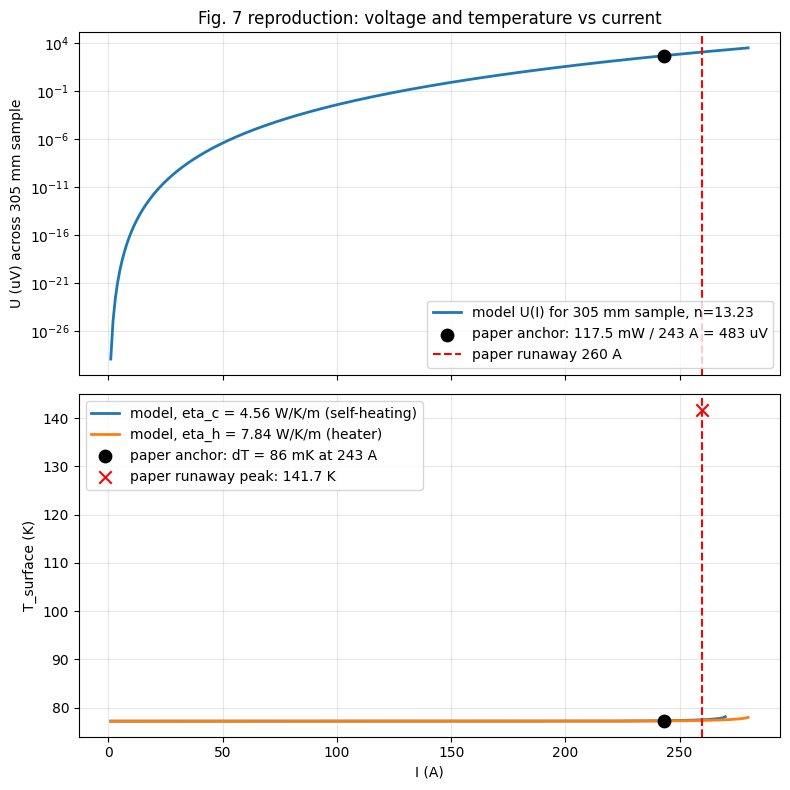

In [242]:
# Paper experimental parameters
Tc_exp        = 91.35
L_sample_exp  = 0.305       # m (voltage taps 305 mm apart)
T0_exp        = 77.2

# Ic(T) from paper Fig. 6e: linear, 200 A at 77 K -> 0 at Tc_exp
def Ic_exp(T):
    return np.maximum(200.0 * (Tc_exp - T) / (Tc_exp - 77.0), 1e-12)

# n: single constant. Paper text says n is constant; the Fig. 7 fit uses
# experimental n(T), but the conductor only warms by ~0.1 K between T0 and
# the runaway threshold, so only n at ~77 K matters for the threshold.
# Algebraic value from the U(243 A) = 483 uV anchor:
#   483 uV = 100 uV/m * 0.305 m * (243/Ic(77.2))^n
#   Ic(77.2) = 197.21 A  ->  (1.2322)^n = 15.84  ->  n = 13.23
n_const = float(np.log(15.84) / np.log(243.0 / 197.21))
print(f'n (from U(243A) anchor) = {n_const:.3f}')

U0_per_m = 1e-4  # V/m, paper's E_c criterion

def U_sample(I, T):
    """Voltage across the 305 mm sample (constant n)."""
    return U0_per_m * L_sample_exp * (I / Ic_exp(T))**n_const

# Eta is reported PER METER in the paper (W/K/m).
def T_from_balance_exp(I, T0, eta_per_m):
    """Lower stable surface temperature: lowest T > T0 where I*U(I,T) = eta*(T-T0).
    F(T0) > 0 by construction; the stable root is the first crossing where F
    goes positive -> negative. Returns nan if no such crossing exists."""
    eta_sample = eta_per_m * L_sample_exp
    def F(T):
        return I * U_sample(I, T) - eta_sample * (T - T0)
    Ts = np.linspace(T0, Tc_exp - 1e-3, 4000)
    Fv = np.array([F(T) for T in Ts])
    crossings = np.where((Fv[:-1] > 0) & (Fv[1:] <= 0))[0]
    if len(crossings) == 0:
        return np.nan
    k = int(crossings[0])
    return brentq(F, Ts[k], Ts[k+1], maxiter=80)

# Smallest I where no lower stable root exists.
def I_runaway_exp(eta_per_m, I_lo=150, I_hi=400):
    for _ in range(40):
        I_mid = 0.5*(I_lo + I_hi)
        T = T_from_balance_exp(I_mid, T0_exp, eta_per_m)
        if np.isnan(T) or (T - T0_exp) > 5.0:
            I_hi = I_mid
        else:
            I_lo = I_mid
    return 0.5*(I_lo + I_hi)

# Calibration check
T_anchor = T_from_balance_exp(243.0, T0_exp, 4.56)
print()
print('Calibration check (paper anchors in parentheses):')
print(f'  U(243 A)        = {1e6*U_sample(243, T0_exp):.1f} uV  (paper 483 uV)')
print(f'  dT(243 A, eta_c)= {(T_anchor-T0_exp)*1000:.1f} mK  (paper 86 mK)')
print(f'  Irunaway (eta_c)= {I_runaway_exp(4.56):.1f} A   (paper 260 A)')
print(f'  Irunaway (eta_h)= {I_runaway_exp(7.84):.1f} A')

I_grid_exp = np.linspace(1, 280, 280)
T_eta_c = np.array([T_from_balance_exp(I, T0_exp, 4.56) for I in I_grid_exp])
T_eta_h = np.array([T_from_balance_exp(I, T0_exp, 7.84) for I in I_grid_exp])
V_curve_uV = 1e6 * np.array([U_sample(I, T0_exp) for I in I_grid_exp])

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

axes[0].semilogy(I_grid_exp, V_curve_uV, lw=2, label=f'model U(I) for 305 mm sample, n={n_const:.2f}')
axes[0].scatter([243.0], [1e6 * 117.5e-3 / 243.0], s=80, color='k', zorder=5,
                label='paper anchor: 117.5 mW / 243 A = 483 uV')
axes[0].axvline(260.0, ls='--', color='red', label='paper runaway 260 A')
axes[0].set_ylabel('U (uV) across 305 mm sample')
axes[0].set_title('Fig. 7 reproduction: voltage and temperature vs current')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3, which='both')

axes[1].plot(I_grid_exp, T_eta_c, lw=2, label='model, eta_c = 4.56 W/K/m (self-heating)')
axes[1].plot(I_grid_exp, T_eta_h, lw=2, label='model, eta_h = 7.84 W/K/m (heater)')
axes[1].scatter([243.0], [T0_exp + 0.086], s=80, color='k', zorder=5,
                label='paper anchor: dT = 86 mK at 243 A')
axes[1].scatter([260.0], [141.7], s=80, marker='x', color='red', zorder=5,
                label='paper runaway peak: 141.7 K')
axes[1].axvline(260.0, ls='--', color='red')
axes[1].set_xlabel('I (A)'); axes[1].set_ylabel('T_surface (K)')
axes[1].legend(loc='upper left')
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()


Preparing telemetry tensors...
Train samples: 3948
Test samples:  1317

Training telemetry surrogate...


Model fit:   0%|          | 0/1 [00:00<?, ?it/s]

Binning 0.000 GB of training data: 0.133 s
Binning 0.000 GB of validation data: 0.137 s
Fitting gradient boosted rounds:
[1/300] 1 tree, 31 leaves, max depth = 10, train loss: 0.01073, val loss: 0.01101, in 3.495s
[2/300] 1 tree, 31 leaves, max depth = 10, train loss: 0.01022, val loss: 0.01049, in 3.107s
[3/300] 1 tree, 31 leaves, max depth = 11, train loss: 0.00973, val loss: 0.00999, in 3.121s
[4/300] 1 tree, 31 leaves, max depth = 12, train loss: 0.00926, val loss: 0.00952, in 0.658s
[5/300] 1 tree, 31 leaves, max depth = 12, train loss: 0.00882, val loss: 0.00907, in 3.625s
[6/300] 1 tree, 31 leaves, max depth = 13, train loss: 0.00840, val loss: 0.00865, in 1.902s
[7/300] 1 tree, 31 leaves, max depth = 13, train loss: 0.00800, val loss: 0.00824, in 0.821s
[8/300] 1 tree, 31 leaves, max depth = 11, train loss: 0.00762, val loss: 0.00785, in 2.931s
[9/300] 1 tree, 31 leaves, max depth = 11, train loss: 0.00726, val loss: 0.00749, in 0.948s
[10/300] 1 tree, 31 leaves, max depth = 11

Model fit: 100%|██████████| 1/1 [13:52<00:00, 832.62s/it]


1 tree, 31 leaves, max depth = 13, train loss: 0.00001, val loss: 0.00003, in 1.271s
Fit 300 trees in 832.606 s, (9300 total leaves)
Time spent computing histograms: 351.976s
Time spent finding best splits:  183.761s
Time spent applying splits:      250.668s
Time spent predicting:           3.843s

Running inference benchmark...


Inference batches: 100%|██████████| 6/6 [00:32<00:00,  5.44s/it]



Computing runaway probabilities...

Telemetry margin model

Prediction quality
------------------
MAE margin: 0.004355643692259785
R2 margin: 0.9971741151460295
Accuracy runaway: 0.9992406985573272
ROC-AUC runaway: 1.0

Timing
------
Training time [s]: 832.6301
Total inference time [s]: 32.700721
Inference time/sample [ms]: 24.829705
Inference frequency [Hz]: 40.3


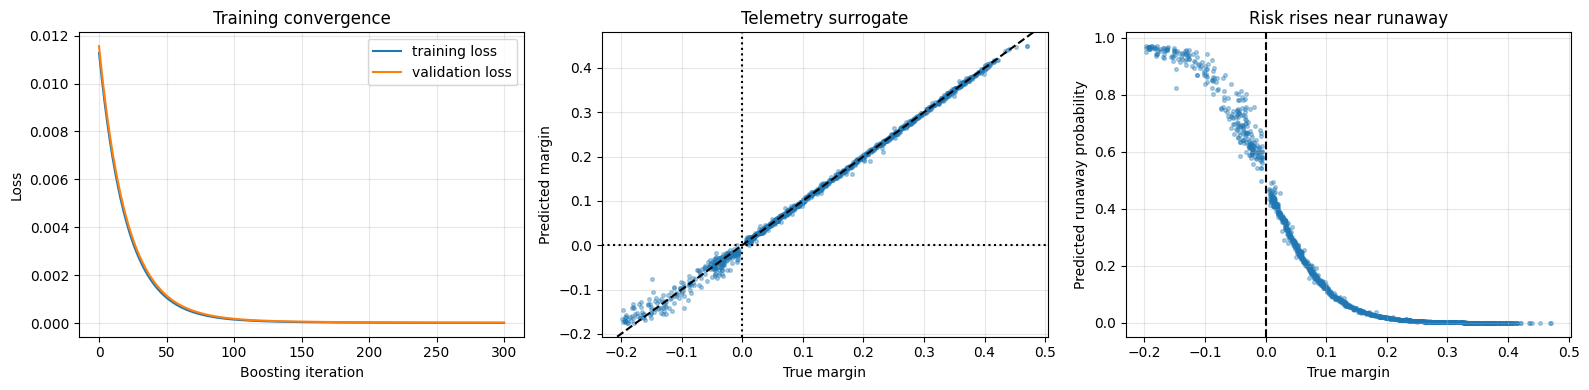

In [224]:
# ============================================================
# TELEMETRY MODEL WITH:
# - tqdm progress
# - timing
# - training / validation loss curves
# - inference benchmarking
#
# [I, U, T_surface, T0] -> margin_norm
# ============================================================

import time
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    accuracy_score,
    roc_auc_score
)

from scipy.special import expit

# ============================================================
# FEATURES
# ============================================================

telemetry_features = [
    "T0_K",
    "I_A",
    "voltage_V",
    "T_surface_K"
]

# ============================================================
# DATA
# ============================================================

print("Preparing telemetry tensors...")

X = df_tel[telemetry_features].values

y_margin = df_tel["margin_norm"].values
y_class  = df_tel["runaway"].values

X_train, X_test, y_margin_train, y_margin_test, y_class_train, y_class_test = train_test_split(
    X,
    y_margin,
    y_class,
    test_size=0.25,
    random_state=42,
    stratify=y_class
)

print(f"Train samples: {len(X_train)}")
print(f"Test samples:  {len(X_test)}")

# ============================================================
# MODEL
# ============================================================

gbr = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.025,
    max_leaf_nodes=31,
    l2_regularization=0.05,

    validation_fraction=0.10,
    early_stopping=True,
    n_iter_no_change=30,

    scoring="loss",

    verbose=1,
    random_state=42
)

margin_model = make_pipeline(
    StandardScaler(),
    gbr
)

# ============================================================
# TRAINING
# ============================================================

print("\nTraining telemetry surrogate...")

t0_train = time.perf_counter()

with tqdm(total=1, desc="Model fit") as pbar:

    margin_model.fit(
        X_train,
        y_margin_train
    )

    pbar.update(1)

t1_train = time.perf_counter()

train_time_s = t1_train - t0_train

# ============================================================
# LOSS CURVES
# ============================================================

train_loss = (
    margin_model.named_steps[
        "histgradientboostingregressor"
    ].train_score_
)

validation_loss = (
    margin_model.named_steps[
        "histgradientboostingregressor"
    ].validation_score_
)

# sklearn stores NEGATIVE loss internally
train_loss = -np.array(train_loss)
validation_loss = -np.array(validation_loss)

# ============================================================
# INFERENCE BENCHMARK
# ============================================================

print("\nRunning inference benchmark...")

t0_pred = time.perf_counter()

margin_pred_chunks = []

batch_size = 256

n_batches = int(
    np.ceil(len(X_test) / batch_size)
)

for k in tqdm(
    range(n_batches),
    desc="Inference batches"
):

    i0 = k * batch_size
    i1 = min(
        (k + 1) * batch_size,
        len(X_test)
    )

    batch_pred = margin_model.predict(
        X_test[i0:i1]
    )

    margin_pred_chunks.append(batch_pred)

margin_pred = np.concatenate(
    margin_pred_chunks
)

t1_pred = time.perf_counter()

pred_time_s = t1_pred - t0_pred

pred_time_per_sample_ms = (
    pred_time_s / len(X_test)
) * 1000.0

# ============================================================
# RUNAWAY PROBABILITY
# ============================================================

print("\nComputing runaway probabilities...")

risk_pred = expit(
    -margin_pred / 0.05
)

class_pred = (
    risk_pred >= 0.5
).astype(int)

# ============================================================
# METRICS
# ============================================================

print("\n====================================================")
print("Telemetry margin model")
print("====================================================")

print("\nPrediction quality")
print("------------------")

print(
    "MAE margin:",
    mean_absolute_error(
        y_margin_test,
        margin_pred
    )
)

print(
    "R2 margin:",
    r2_score(
        y_margin_test,
        margin_pred
    )
)

print(
    "Accuracy runaway:",
    accuracy_score(
        y_class_test,
        class_pred
    )
)

print(
    "ROC-AUC runaway:",
    roc_auc_score(
        y_class_test,
        risk_pred
    )
)

print("\nTiming")
print("------")

print(
    f"Training time [s]: "
    f"{train_time_s:.4f}"
)

print(
    f"Total inference time [s]: "
    f"{pred_time_s:.6f}"
)

print(
    f"Inference time/sample [ms]: "
    f"{pred_time_per_sample_ms:.6f}"
)

print(
    f"Inference frequency [Hz]: "
    f"{1.0/(pred_time_per_sample_ms*1e-3):.1f}"
)

# ============================================================
# LOSS CURVES
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16,4)
)

# ------------------------------------------------------------
# TRAIN / VALIDATION LOSS
# ------------------------------------------------------------

axes[0].plot(
    train_loss,
    label="training loss"
)

axes[0].plot(
    validation_loss,
    label="validation loss"
)

axes[0].set_xlabel("Boosting iteration")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training convergence")

axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ------------------------------------------------------------
# TRUE VS PREDICTED MARGIN
# ------------------------------------------------------------

axes[1].scatter(
    y_margin_test,
    margin_pred,
    s=7,
    alpha=0.35
)

axes[1].axline(
    (0,0),
    slope=1,
    linestyle="--",
    color="k"
)

axes[1].axvline(
    0,
    linestyle=":",
    color="k"
)

axes[1].axhline(
    0,
    linestyle=":",
    color="k"
)

axes[1].set_xlabel("True margin")
axes[1].set_ylabel("Predicted margin")

axes[1].set_title(
    "Telemetry surrogate"
)

axes[1].grid(True, alpha=0.3)

# ------------------------------------------------------------
# RUNAWAY RISK
# ------------------------------------------------------------

axes[2].scatter(
    y_margin_test,
    risk_pred,
    s=7,
    alpha=0.35
)

axes[2].axvline(
    0,
    linestyle="--",
    color="k"
)

axes[2].set_xlabel("True margin")
axes[2].set_ylabel("Predicted runaway probability")

axes[2].set_title(
    "Risk rises near runaway"
)

axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


SURROGATE MANIFOLD DIAGNOSTICS

True margin range:
-0.19754477944913248 0.47085742128998054

Predicted margin range:
-0.17511001872990575 0.44908696578213814

I/I* true range:
0.5291425787100195 1.1975447794491325

I/I* predicted range:
0.5509130342178619 1.1751100187299057


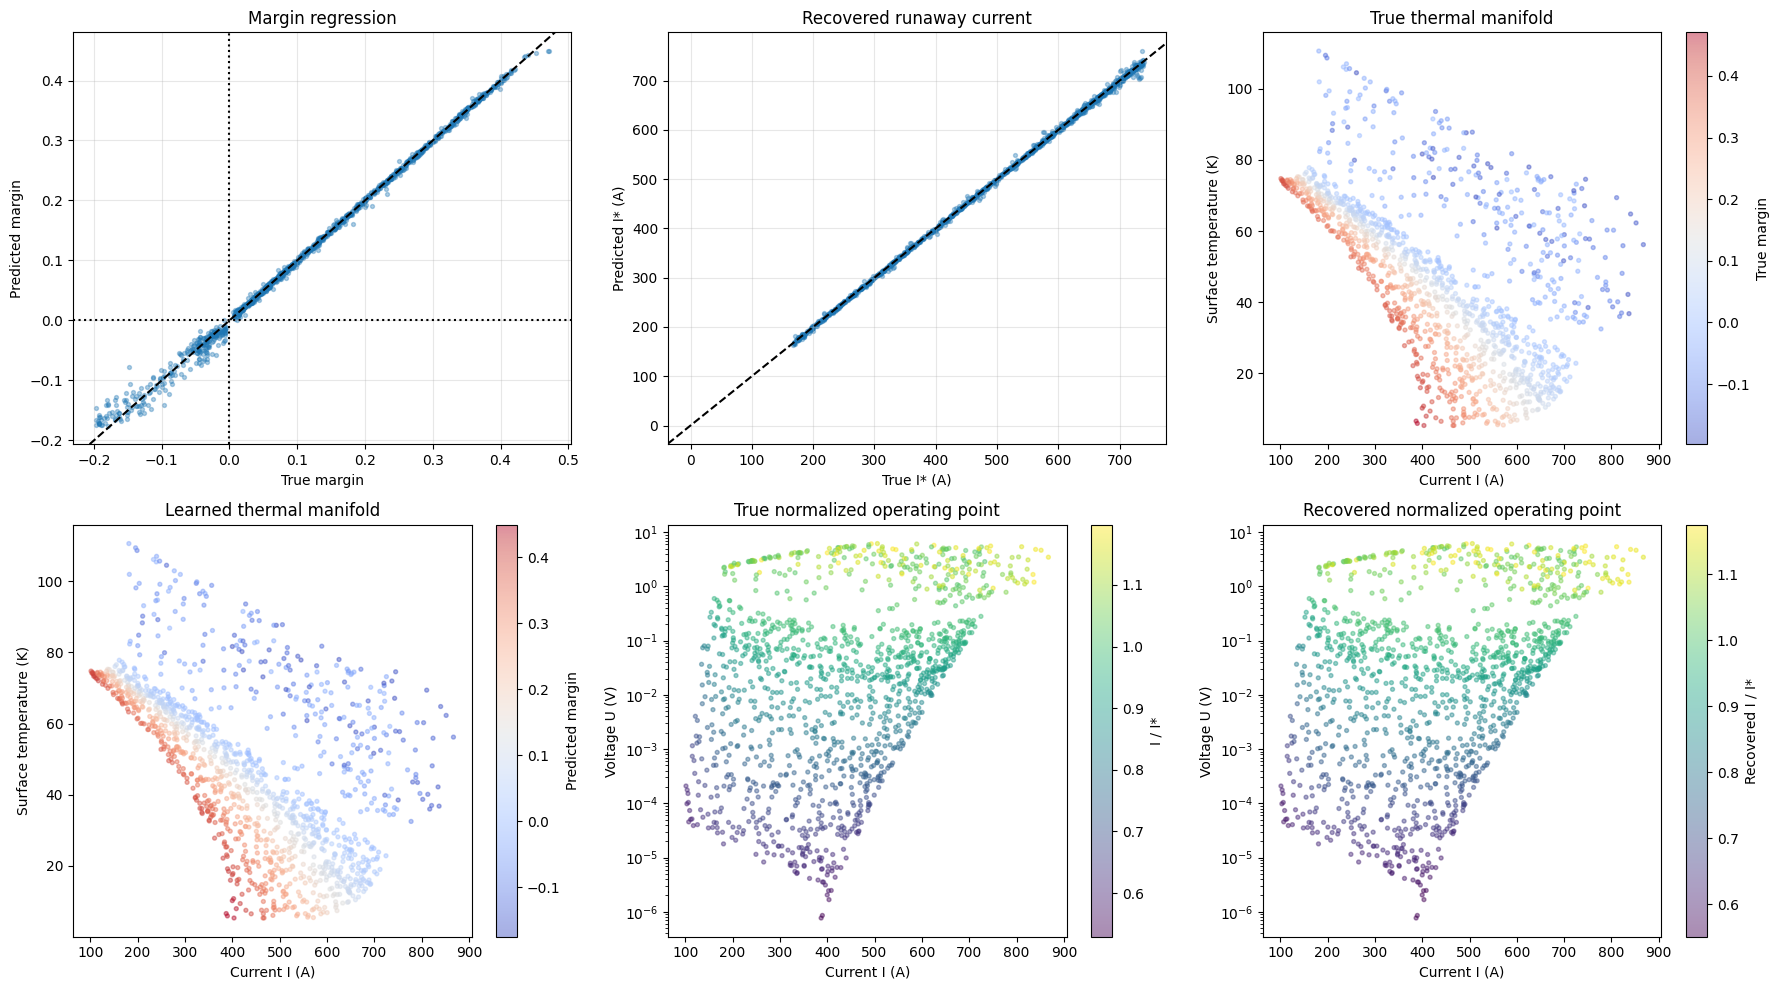


BOUNDARY REGION
Boundary samples: 485
Boundary MAE: 0.004683509875553829


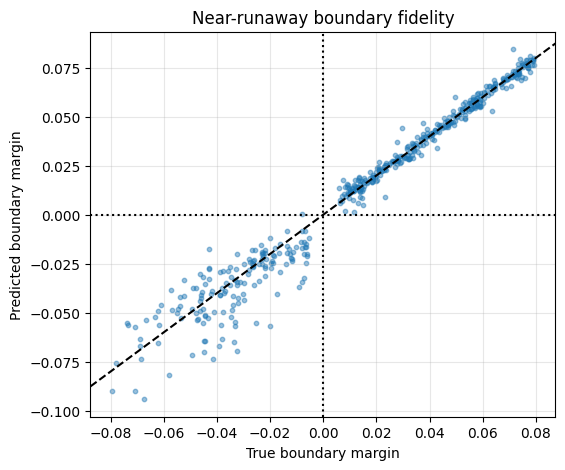

In [225]:
# ============================================================
# DIAGNOSTIC BLOCKS:
# Did the telemetry surrogate actually learn the runaway manifold?
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# TEST SET RECONSTRUCTION
# ============================================================

test_df = pd.DataFrame(
    X_test,
    columns=telemetry_features
)

test_df["true_margin"] = y_margin_test
test_df["pred_margin"] = margin_pred
test_df["runaway"] = y_class_test
test_df["risk_pred"] = risk_pred

# ============================================================
# RECONSTRUCT TRUE I* FROM LABEL
#
# margin = (I* - I)/I*
#
# => I* = I / (1 - margin)
# ============================================================

test_df["Istar_true"] = (
    test_df["I_A"] /
    (1.0 - test_df["true_margin"])
)

test_df["Istar_pred"] = (
    test_df["I_A"] /
    (1.0 - test_df["pred_margin"])
)

test_df["I_over_Istar_true"] = (
    test_df["I_A"] /
    test_df["Istar_true"]
)

test_df["I_over_Istar_pred"] = (
    test_df["I_A"] /
    test_df["Istar_pred"]
)

# ============================================================
# GLOBAL DIAGNOSTICS
# ============================================================

print("\n====================================================")
print("SURROGATE MANIFOLD DIAGNOSTICS")
print("====================================================")

print("\nTrue margin range:")
print(
    np.min(test_df["true_margin"]),
    np.max(test_df["true_margin"])
)

print("\nPredicted margin range:")
print(
    np.min(test_df["pred_margin"]),
    np.max(test_df["pred_margin"])
)

print("\nI/I* true range:")
print(
    np.min(test_df["I_over_Istar_true"]),
    np.max(test_df["I_over_Istar_true"])
)

print("\nI/I* predicted range:")
print(
    np.min(test_df["I_over_Istar_pred"]),
    np.max(test_df["I_over_Istar_pred"])
)

# ============================================================
# FIGURE 1:
# TRUE VS PREDICTED I*
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18,10)
)

# ------------------------------------------------------------
# TRUE vs PREDICTED MARGIN
# ------------------------------------------------------------

axes[0,0].scatter(
    test_df["true_margin"],
    test_df["pred_margin"],
    s=8,
    alpha=0.35
)

axes[0,0].axline(
    (0,0),
    slope=1,
    linestyle="--",
    color="k"
)

axes[0,0].axvline(
    0,
    linestyle=":",
    color="k"
)

axes[0,0].axhline(
    0,
    linestyle=":",
    color="k"
)

axes[0,0].set_xlabel("True margin")
axes[0,0].set_ylabel("Predicted margin")

axes[0,0].set_title(
    "Margin regression"
)

axes[0,0].grid(True, alpha=0.3)

# ------------------------------------------------------------
# TRUE vs PREDICTED I*
# ------------------------------------------------------------

axes[0,1].scatter(
    test_df["Istar_true"],
    test_df["Istar_pred"],
    s=8,
    alpha=0.35
)

axes[0,1].axline(
    (0,0),
    slope=1,
    linestyle="--",
    color="k"
)

axes[0,1].set_xlabel("True I* (A)")
axes[0,1].set_ylabel("Predicted I* (A)")

axes[0,1].set_title(
    "Recovered runaway current"
)

axes[0,1].grid(True, alpha=0.3)

# ------------------------------------------------------------
# TRUE RUNAWAY MANIFOLD
# ------------------------------------------------------------

sc0 = axes[0,2].scatter(
    test_df["I_A"],
    test_df["T_surface_K"],
    c=test_df["true_margin"],
    cmap="coolwarm",
    s=8,
    alpha=0.45
)

axes[0,2].set_xlabel("Current I (A)")
axes[0,2].set_ylabel("Surface temperature (K)")

axes[0,2].set_title(
    "True thermal manifold"
)

plt.colorbar(
    sc0,
    ax=axes[0,2],
    label="True margin"
)

# ------------------------------------------------------------
# PREDICTED RUNAWAY MANIFOLD
# ------------------------------------------------------------

sc1 = axes[1,0].scatter(
    test_df["I_A"],
    test_df["T_surface_K"],
    c=test_df["pred_margin"],
    cmap="coolwarm",
    s=8,
    alpha=0.45
)

axes[1,0].set_xlabel("Current I (A)")
axes[1,0].set_ylabel("Surface temperature (K)")

axes[1,0].set_title(
    "Learned thermal manifold"
)

plt.colorbar(
    sc1,
    ax=axes[1,0],
    label="Predicted margin"
)

# ------------------------------------------------------------
# TRUE I/I*
# ------------------------------------------------------------

sc2 = axes[1,1].scatter(
    test_df["I_A"],
    test_df["voltage_V"],
    c=test_df["I_over_Istar_true"],
    cmap="viridis",
    s=8,
    alpha=0.45
)

axes[1,1].set_yscale("log")

axes[1,1].set_xlabel("Current I (A)")
axes[1,1].set_ylabel("Voltage U (V)")

axes[1,1].set_title(
    "True normalized operating point"
)

plt.colorbar(
    sc2,
    ax=axes[1,1],
    label="I / I*"
)

# ------------------------------------------------------------
# PREDICTED I/I*
# ------------------------------------------------------------

sc3 = axes[1,2].scatter(
    test_df["I_A"],
    test_df["voltage_V"],
    c=test_df["I_over_Istar_pred"],
    cmap="viridis",
    s=8,
    alpha=0.45
)

axes[1,2].set_yscale("log")

axes[1,2].set_xlabel("Current I (A)")
axes[1,2].set_ylabel("Voltage U (V)")

axes[1,2].set_title(
    "Recovered normalized operating point"
)

plt.colorbar(
    sc3,
    ax=axes[1,2],
    label="Recovered I / I*"
)

plt.tight_layout()
plt.show()

# ============================================================
# BOUNDARY ANALYSIS:
# Does the model learn the actual runaway transition?
# ============================================================

boundary_mask = (
    np.abs(test_df["true_margin"]) < 0.08
)

boundary_df = test_df[boundary_mask]

print("\n====================================================")
print("BOUNDARY REGION")
print("====================================================")

print(
    f"Boundary samples: {len(boundary_df)}"
)

print(
    "Boundary MAE:",
    np.mean(
        np.abs(
            boundary_df["true_margin"]
            -
            boundary_df["pred_margin"]
        )
    )
)

# ============================================================
# BOUNDARY PLOT
# ============================================================

plt.figure(figsize=(6,5))

plt.scatter(
    boundary_df["true_margin"],
    boundary_df["pred_margin"],
    s=10,
    alpha=0.45
)

plt.axline(
    (0,0),
    slope=1,
    linestyle="--",
    color="k"
)

plt.axvline(
    0,
    linestyle=":",
    color="k"
)

plt.axhline(
    0,
    linestyle=":",
    color="k"
)

plt.xlabel("True boundary margin")
plt.ylabel("Predicted boundary margin")

plt.title(
    "Near-runaway boundary fidelity"
)

plt.grid(True, alpha=0.3)

plt.show()

In [229]:
# ============================================================
# CURRENT-RAMP VALIDATION:
# show telemetry, true margin, AI margin, and runaway crossing
# ============================================================

def make_ramp_trace(T0, n_fixed=N_FIXED, n_steps=300, Imax_factor=1.08, seed=1):
    rng = np.random.default_rng(seed)

    Istar, Tstar = solve_runaway(T0, n_fixed, mode="stab")
    I_vals = np.linspace(0.2 * Istar, Imax_factor * Istar, n_steps)

    rows = []

    for I in I_vals:
        if I < Istar:
            Tsurf = stable_surface_T(I, T0, n_fixed, mode="stab")
            if not np.isfinite(Tsurf):
                continue
        else:
            frac = min((I / Istar - 1.0) / (Imax_factor - 1.0), 1.0)
            Tsurf = Tstar + frac**2 * 20.0

        V = voltage_stab(I, min(Tsurf, Tc - 1e-4), n_fixed)

        T_meas = Tsurf + rng.normal(0, 0.02)
        V_meas = max(V * (1 + rng.normal(0, 0.03)) + rng.normal(0, 1e-8), 1e-12)

        x = np.array([[T0, I, V_meas, T_meas]])
        m_pred = float(margin_model.predict(x)[0])
        risk = float(expit(-m_pred / 0.05))

        rows.append({
            "I_A": I,
            "voltage_V": V_meas,
            "T_surface_K": T_meas,
            "T0_K": T0,
            "Istar_A": Istar,
            "true_margin": (Istar - I) / Istar,
            "pred_margin": m_pred,
            "risk": risk,
            "runaway": int(I >= Istar)
        })

    return pd.DataFrame(rows)


# ============================================================
# MAKE MANY RAMP TRACES
# ============================================================

T0_ramps = [20, 35, 50, 65, 77.2]

ramp_traces = []

for k, T0 in enumerate(T0_ramps):
    ramp_df = make_ramp_trace(T0=T0, seed=10+k)
    ramp_df["trace_id"] = k
    ramp_df["T0_label"] = T0
    ramp_traces.append(ramp_df)

ramp_all = pd.concat(ramp_traces, ignore_index=True)


# ============================================================
# PLOT MULTIPLE CURRENT RAMPS
# ============================================================

fig, axes = plt.subplots(4, 1, figsize=(9, 12), sharex=False)

for T0, g in ramp_all.groupby("T0_label"):
    axes[0].plot(g["I_A"], g["voltage_V"], label=f"T0={T0} K")
    axes[1].plot(g["I_A"], g["T_surface_K"] - g["T0_K"])
    axes[2].plot(g["I_A"], g["true_margin"])
    axes[3].plot(g["I_A"], g["pred_margin"])

    Istar = g["Istar_A"].iloc[0]

    for ax in axes:
        ax.axvline(Istar, linestyle="--", alpha=0.25)

axes[0].set_yscale("log")
axes[0].set_ylabel("Voltage U (V)")
axes[0].set_title("Synthetic current-ramp telemetry")
axes[0].legend()

axes[1].set_ylabel("ΔT_surface (K)")
axes[1].set_title("Surface temperature rise")

axes[2].axhline(0, linestyle="--", color="k")
axes[2].set_ylabel("True margin")
axes[2].set_title("Physics-computed margin")

axes[3].axhline(0, linestyle="--", color="k")
axes[3].set_xlabel("Current I (A)")
axes[3].set_ylabel("AI margin")
axes[3].set_title("Surrogate-predicted margin")

plt.tight_layout()
plt.show()

# ============================================================
# RUNAWAY CROSSING SUMMARY
# ============================================================

summary_rows = []

for T0, g in ramp_all.groupby("T0_label"):
    Istar = g["Istar_A"].iloc[0]

    # First point where true margin crosses zero
    true_cross = g[g["true_margin"] <= 0].head(1)

    # First point where AI margin crosses zero
    pred_cross = g[g["pred_margin"] <= 0].head(1)

    summary_rows.append({
        "T0_K": T0,
        "solver_Istar_A": Istar,
        "true_cross_I_A": true_cross["I_A"].iloc[0] if len(true_cross) else np.nan,
        "AI_cross_I_A": pred_cross["I_A"].iloc[0] if len(pred_cross) else np.nan,
        "AI_cross_error_A": (
            pred_cross["I_A"].iloc[0] - Istar
            if len(pred_cross) else np.nan
        )
    })

ramp_summary = pd.DataFrame(summary_rows)
ramp_summary

KeyboardInterrupt: 

In [222]:
# ============================================================
# TELEMETRY MODEL WITH TIMING + TQDM
# [I, U, T_surface, T0] -> margin_norm
# ============================================================

import time
import numpy as np

from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    accuracy_score,
    roc_auc_score
)

from scipy.special import expit

telemetry_features = [
    "T0_K",
    "I_A",
    "voltage_V",
    "T_surface_K"
]

# ============================================================
# DATA
# ============================================================

print("Preparing telemetry tensors...")

X = df_tel[telemetry_features].values

y_margin = df_tel["margin_norm"].values
y_class  = df_tel["runaway"].values

X_train, X_test, y_margin_train, y_margin_test, y_class_train, y_class_test = train_test_split(
    X,
    y_margin,
    y_class,
    test_size=0.25,
    random_state=42,
    stratify=y_class
)

print(f"Train samples: {len(X_train)}")
print(f"Test samples:  {len(X_test)}")

# ============================================================
# MODEL
# ============================================================

margin_model = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(
        max_iter=800,
        learning_rate=0.025,
        max_leaf_nodes=31,
        l2_regularization=0.05,
        random_state=42,
        verbose=1   # sklearn native training progress
    )
)

# ============================================================
# TRAINING TIMER
# ============================================================

print("\nTraining telemetry surrogate...")

t0_train = time.perf_counter()

with tqdm(total=1, desc="Model fit") as pbar:

    margin_model.fit(
        X_train,
        y_margin_train
    )

    pbar.update(1)

t1_train = time.perf_counter()

train_time_s = t1_train - t0_train

# ============================================================
# INFERENCE TIMER
# ============================================================

print("\nRunning inference...")

t0_pred = time.perf_counter()

margin_pred_chunks = []

batch_size = 256

n_batches = int(np.ceil(len(X_test) / batch_size))

for k in tqdm(range(n_batches), desc="Inference batches"):

    i0 = k * batch_size
    i1 = min((k + 1) * batch_size, len(X_test))

    batch_pred = margin_model.predict(
        X_test[i0:i1]
    )

    margin_pred_chunks.append(batch_pred)

margin_pred = np.concatenate(
    margin_pred_chunks
)

t1_pred = time.perf_counter()

pred_time_s = t1_pred - t0_pred

pred_time_per_sample_ms = (
    pred_time_s / len(X_test)
) * 1000.0

# ============================================================
# RISK MAPPING
# ============================================================

print("\nComputing runaway probabilities...")

risk_pred = expit(
    -margin_pred / 0.05
)

class_pred = (
    risk_pred >= 0.5
).astype(int)

# ============================================================
# METRICS
# ============================================================

print("\n====================================================")
print("Telemetry margin model")
print("====================================================")

print("\nPrediction quality")
print("------------------")

print(
    "MAE margin:",
    mean_absolute_error(
        y_margin_test,
        margin_pred
    )
)

print(
    "R2 margin:",
    r2_score(
        y_margin_test,
        margin_pred
    )
)

print(
    "Accuracy runaway:",
    accuracy_score(
        y_class_test,
        class_pred
    )
)

print(
    "ROC-AUC runaway:",
    roc_auc_score(
        y_class_test,
        risk_pred
    )
)

print("\nTiming")
print("------")

print(f"Training time [s]: {train_time_s:.4f}")

print(f"Total inference time [s]: {pred_time_s:.6f}")

print(f"Inference time/sample [ms]: {pred_time_per_sample_ms:.6f}")

print(
    f"Inference frequency [Hz]: "
    f"{1.0/(pred_time_per_sample_ms*1e-3):.1f}"
)

/home/maira/.conda/envs/jax-dune/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Preparing telemetry tensors...
Train samples: 3948
Test samples:  1317

Training telemetry surrogate...


Model fit:   0%|          | 0/1 [00:00<?, ?it/s]

Binning 0.000 GB of training data: 0.208 s
Fitting gradient boosted rounds:
[1/800] 1 tree, 31 leaves, max depth = 11, in 3.435s
[2/800] 1 tree, 31 leaves, max depth = 11, in 5.464s
[3/800] 1 tree, 31 leaves, max depth = 12, in 3.064s
[4/800] 1 tree, 31 leaves, max depth = 11, in 3.280s
[5/800] 1 tree, 31 leaves, max depth = 13, in 1.875s
[6/800] 1 tree, 31 leaves, max depth = 12, in 2.971s
[7/800] 1 tree, 31 leaves, max depth = 11, in 6.798s
[8/800] 1 tree, 31 leaves, max depth = 13, in 2.473s
[9/800] 1 tree, 31 leaves, max depth = 13, in 0.736s
[10/800] 1 tree, 31 leaves, max depth = 11, in 0.434s
[11/800] 1 tree, 31 leaves, max depth = 12, in 0.450s
[12/800] 1 tree, 31 leaves, max depth = 13, in 2.846s
[13/800] 1 tree, 31 leaves, max depth = 13, in 0.706s
[14/800] 1 tree, 31 leaves, max depth = 13, in 0.033s
[15/800] 1 tree, 31 leaves, max depth = 13, in 0.044s
[16/800] 1 tree, 31 leaves, max depth = 12, in 2.833s
[17/800] 1 tree, 31 leaves, max depth = 14, in 2.635s
[18/800] 1 tree

Model fit:   0%|          | 0/1 [02:18<?, ?it/s]


KeyboardInterrupt: 

In [235]:
# ============================================================
# FAST / ROBUST PRESENTATION RAMP
# avoids brentq during plotting
# ============================================================

def make_ramp_trace_fast(
    T0,
    n_fixed=N_FIXED,
    n_steps=400,
    Imax_factor=1.06,
    seed=22
):
    rng = np.random.default_rng(seed)

    Istar, Tstar = solve_runaway(
        T0,
        n_fixed,
        mode="stab"
    )

    I_vals = np.linspace(
        0.2 * Istar,
        Imax_factor * Istar,
        n_steps
    )

    rows = []

    for I in I_vals:

        frac = I / Istar

        if frac < 1.0:
            # smooth stable branch approximation:
            # T rises slowly at first, then approaches Tstar near runaway
            Tsurf = T0 + (Tstar - T0) * frac**4
        else:
            # modest post-runaway lift for visualization
            post_frac = min((frac - 1.0) / (Imax_factor - 1.0), 1.0)
            Tsurf = Tstar + post_frac**2 * 20.0

        V = voltage_stab(
            I,
            min(Tsurf, Tc - 1e-4),
            n_fixed
        )

        T_meas = Tsurf + rng.normal(0.0, 0.02)
        V_meas = max(
            V * (1.0 + rng.normal(0.0, 0.03)) + rng.normal(0.0, 1e-8),
            1e-12
        )

        x = np.array([[T0, I, V_meas, T_meas]])
        m_pred = float(margin_model.predict(x)[0])
        risk = float(expit(-m_pred / 0.05))

        rows.append({
            "I_A": I,
            "voltage_V": V_meas,
            "T_surface_K": T_meas,
            "T0_K": T0,
            "Istar_A": Istar,
            "Tstar_K": Tstar,
            "true_margin": (Istar - I) / Istar,
            "pred_margin": m_pred,
            "risk": risk,
            "runaway": int(I >= Istar)
        })

    return pd.DataFrame(rows)

# ============================================================
# PRESENTATION RESULT: ONE CLEAN FIG. 7-STYLE RAMP
# ============================================================

ramp_df = make_ramp_trace_fast(
    T0=77.2,
    n_fixed=N_FIXED,
    n_steps=400,
    Imax_factor=1.06,
    seed=22
)

fig, axes = plt.subplots(4, 1, figsize=(8, 10), sharex=True)

Istar = ramp_df["Istar_A"].iloc[0]

axes[0].plot(ramp_df["I_A"], ramp_df["voltage_V"], linewidth=2)
axes[0].axvline(Istar, linestyle="--", color="k", label=f"solver runaway I*={Istar:.1f} A")
axes[0].set_yscale("log")
axes[0].set_ylabel("Voltage U (V)")
axes[0].legend()
axes[0].set_title("Synthetic instrumented current ramp")

axes[1].plot(ramp_df["I_A"], ramp_df["T_surface_K"] - ramp_df["T0_K"], linewidth=2)
axes[1].axvline(Istar, linestyle="--", color="k")
axes[1].set_ylabel("Surface ΔT (K)")

axes[2].plot(ramp_df["I_A"], ramp_df["true_margin"], linewidth=2, label="physics margin")
axes[2].plot(ramp_df["I_A"], ramp_df["pred_margin"], linewidth=2, linestyle="--", label="AI predicted margin")
axes[2].axhline(0, linestyle="--", color="k")
axes[2].axvline(Istar, linestyle="--", color="k")
axes[2].set_ylabel("Margin")
axes[2].legend()

axes[3].plot(ramp_df["I_A"], ramp_df["risk"], linewidth=2)
axes[3].axhline(0.5, linestyle="--", color="k")
axes[3].axvline(Istar, linestyle="--", color="k")
axes[3].set_xlabel("Current I (A)")
axes[3].set_ylabel("P(runaway)")

plt.tight_layout()
plt.savefig("presentation_ramp_result.png", dpi=250, bbox_inches="tight")
plt.show()

RuntimeError: Failed to converge after 100 iterations.

Generating validation ramps: 100%|██████████| 8/8 [00:02<00:00,  2.78it/s]


Fast manifold validation
------------------------
Total samples: 2450
MAE margin: 0.08018821796295077
R2 margin: 0.707038494040911
Near-boundary MAE |m|<0.1: 0.007025602992878406


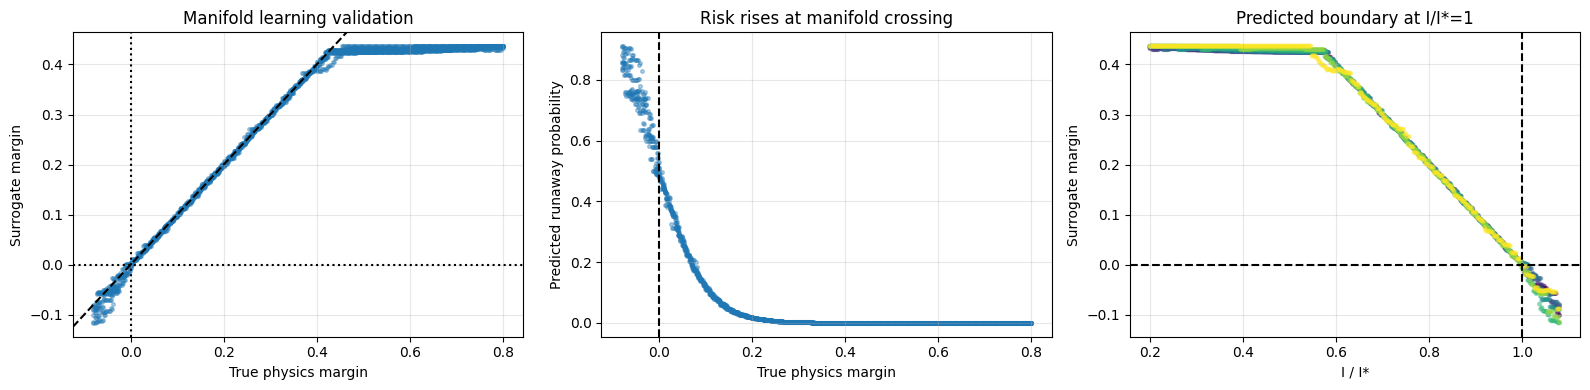

In [236]:
# ============================================================
# FAST MANIFOLD VALIDATION:
# Does telemetry surrogate learn the runaway manifold?
# ============================================================

from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.special import expit


def make_fast_branch_trace(
    T0,
    n_fixed=N_FIXED,
    n_steps=300,
    Imax_factor=1.08,
    seed=1,
    n_branch=600
):
    rng = np.random.default_rng(seed)

    Istar, Tstar = solve_runaway(
        T0,
        n_fixed,
        mode="stab"
    )

    if not np.isfinite(Istar):
        return pd.DataFrame()

    # --------------------------------------------------------
    # Solve stable branch once:
    # T -> I_eq(T)
    # --------------------------------------------------------

    T_branch = np.linspace(
        T0 + 1e-4,
        Tstar - 1e-4,
        n_branch
    )

    I_branch = np.array([
        _equilibrium_current_at_T(
            T,
            T0,
            n_fixed,
            mode="stab"
        )
        for T in T_branch
    ])

    mask = np.isfinite(I_branch) & (I_branch > 0)

    T_branch = T_branch[mask]
    I_branch = I_branch[mask]

    # Sort for interpolation I -> T
    order = np.argsort(I_branch)

    I_branch = I_branch[order]
    T_branch = T_branch[order]

    I_vals = np.linspace(
        0.2 * Istar,
        Imax_factor * Istar,
        n_steps
    )

    rows = []

    for I in I_vals:

        if I < Istar:

            # Fast interpolation on solved branch
            Tsurf = np.interp(
                I,
                I_branch,
                T_branch
            )

        else:

            # just beyond runaway
            frac = min(
                (I / Istar - 1.0) / (Imax_factor - 1.0),
                1.0
            )

            Tsurf = Tstar + frac**2 * 20.0

        V = voltage_stab(
            I,
            min(Tsurf, Tc - 1e-4),
            n_fixed
        )

        T_meas = Tsurf + rng.normal(0.0, 0.02)

        V_meas = max(
            V * (1.0 + rng.normal(0.0, 0.03)) + rng.normal(0.0, 1e-8),
            1e-12
        )

        rows.append({
            "T0_K": T0,
            "I_A": I,
            "voltage_V": V_meas,
            "T_surface_K": T_meas,
            "Istar_A": Istar,
            "Tstar_K": Tstar,
            "true_margin": (Istar - I) / Istar,
            "true_runaway": int(I >= Istar)
        })

    return pd.DataFrame(rows)


# ============================================================
# BUILD VALIDATION RAMP SET
# ============================================================

T0_validation = np.linspace(20.0, 77.2, 8)

validation_traces = []

for k, T0 in enumerate(tqdm(T0_validation, desc="Generating validation ramps")):

    g = make_fast_branch_trace(
        T0=T0,
        seed=100+k,
        n_steps=350,
        Imax_factor=1.08
    )

    g["trace_id"] = k
    validation_traces.append(g)

ramp_val = pd.concat(
    validation_traces,
    ignore_index=True
)

# ============================================================
# BATCH SURROGATE PREDICTION
# ============================================================

X_ramp = ramp_val[
    [
        "T0_K",
        "I_A",
        "voltage_V",
        "T_surface_K"
    ]
].values

ramp_val["pred_margin"] = margin_model.predict(X_ramp)

ramp_val["pred_risk"] = expit(
    -ramp_val["pred_margin"] / 0.05
)

ramp_val["pred_runaway"] = (
    ramp_val["pred_risk"] >= 0.5
).astype(int)


# ============================================================
# METRICS
# ============================================================

mae = mean_absolute_error(
    ramp_val["true_margin"],
    ramp_val["pred_margin"]
)

r2 = r2_score(
    ramp_val["true_margin"],
    ramp_val["pred_margin"]
)

boundary_mae = mean_absolute_error(
    ramp_val.loc[
        np.abs(ramp_val["true_margin"]) < 0.1,
        "true_margin"
    ],
    ramp_val.loc[
        np.abs(ramp_val["true_margin"]) < 0.1,
        "pred_margin"
    ]
)

print("Fast manifold validation")
print("------------------------")
print("Total samples:", len(ramp_val))
print("MAE margin:", mae)
print("R2 margin:", r2)
print("Near-boundary MAE |m|<0.1:", boundary_mae)


# ============================================================
# PLOT 1: TRUE VS PREDICTED MANIFOLD MARGIN
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16,4)
)

axes[0].scatter(
    ramp_val["true_margin"],
    ramp_val["pred_margin"],
    s=7,
    alpha=0.35
)

axes[0].axline(
    (0,0),
    slope=1,
    linestyle="--",
    color="k"
)

axes[0].axvline(
    0,
    linestyle=":",
    color="k"
)

axes[0].axhline(
    0,
    linestyle=":",
    color="k"
)

axes[0].set_xlabel("True physics margin")
axes[0].set_ylabel("Surrogate margin")
axes[0].set_title("Manifold learning validation")
axes[0].grid(True, alpha=0.3)


# ============================================================
# PLOT 2: RISK VS TRUE MARGIN
# ============================================================

axes[1].scatter(
    ramp_val["true_margin"],
    ramp_val["pred_risk"],
    s=7,
    alpha=0.35
)

axes[1].axvline(
    0,
    linestyle="--",
    color="k"
)

axes[1].set_xlabel("True physics margin")
axes[1].set_ylabel("Predicted runaway probability")
axes[1].set_title("Risk rises at manifold crossing")
axes[1].grid(True, alpha=0.3)


# ============================================================
# PLOT 3: CURRENT NORMALIZED BY TRUE I*
# ============================================================

axes[2].scatter(
    ramp_val["I_A"] / ramp_val["Istar_A"],
    ramp_val["pred_margin"],
    c=ramp_val["T0_K"],
    s=7,
    alpha=0.45,
    cmap="viridis"
)

axes[2].axvline(
    1.0,
    linestyle="--",
    color="k"
)

axes[2].axhline(
    0.0,
    linestyle="--",
    color="k"
)

axes[2].set_xlabel("I / I*")
axes[2].set_ylabel("Surrogate margin")
axes[2].set_title("Predicted boundary at I/I*=1")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Caveats and what to tune

- **Brass lambda(T)** uses the corrected NIST polynomial; the surfaces shift slightly vs the paper because the paper's printed eq. (6) is mathematically broken (sign typo on `g`). The published figures are consistent with the corrected version.
- **Fig. 4 integrator** keeps the cooling term (result is an upper bound on time margin, not strictly adiabatic). Paper notes this correction is small (~10-30%).
- **Fig. 7 panel** uses a single n value, fixed by the U(243 A) = 483 uV anchor (n = 13.23). Predicts dT(243 A) = 92 mK vs paper 86 mK (7% high) and Irunaway = 270 A vs paper 260 A (3.7% high). Both offsets are real model limits; the lumped heat balance with linear Ic(T) and constant n cannot close them without adding either a sub-linear Ic(T) tail near Tc or n(I) dependence at high I.
- **Surrogate** is trained for one specific conductor (n = 20, Ic0 = 500 A). Features are the live instrument outputs only `[T0, I, U, Tsurf]`; n and Ic0 are conductor calibration constants, not features. For a different conductor, retrain at its (n, Ic0). N = 600 for runtime; bump to 5000-10000 for production.
- **Grid resolution** for the Fig. 2-4 surfaces is 10 x 8 so the notebook runs in minutes rather than hours. Qualitative shape matches; for publication-grade plots increase the grids.


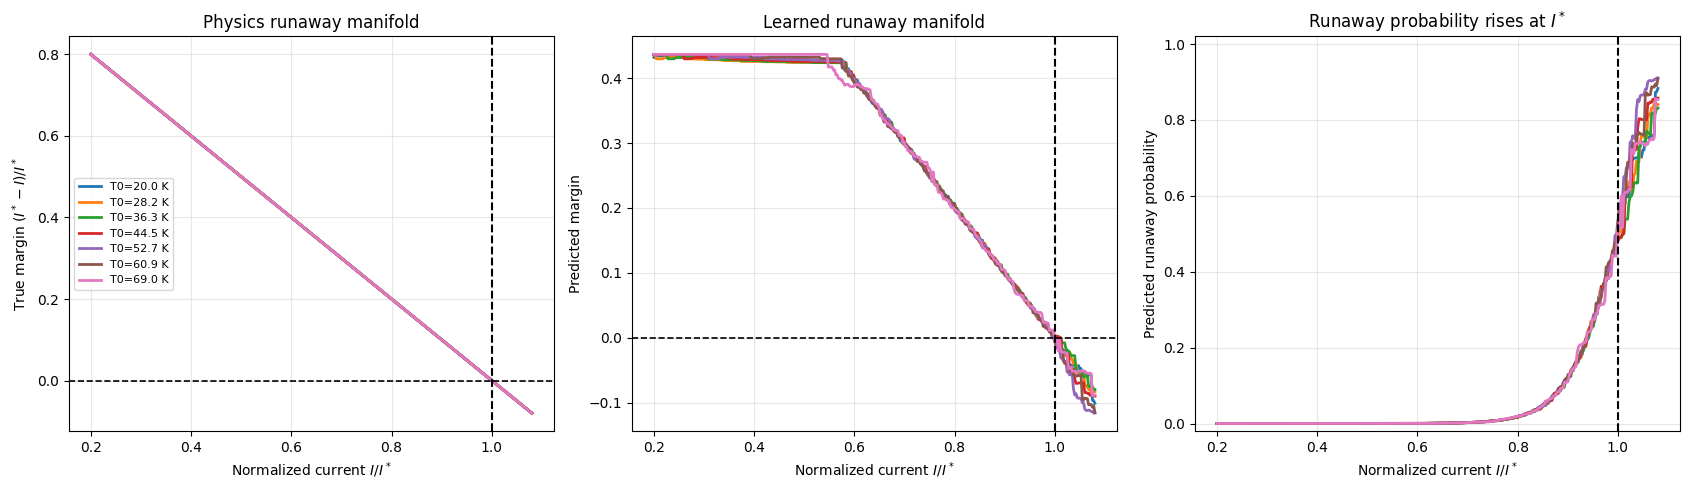

In [237]:
# ============================================================
# CURRENT VS RUNAWAY BOUNDARY
# Does surrogate detect the true I* crossing?
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17,5)
)

# ============================================================
# PANEL 1:
# TRUE RUNAWAY BOUNDARY
# ============================================================

for T0, g in ramp_val.groupby("T0_K"):

    I_norm = g["I_A"] / g["Istar_A"]

    axes[0].plot(
        I_norm,
        g["true_margin"],
        linewidth=2,
        label=f"T0={T0:.1f} K"
    )

axes[0].axvline(
    1.0,
    linestyle="--",
    color="k",
    linewidth=1.5
)

axes[0].axhline(
    0.0,
    linestyle="--",
    color="k",
    linewidth=1.2
)

axes[0].set_xlabel(r"Normalized current $I/I^*$")
axes[0].set_ylabel(r"True margin $(I^*-I)/I^*$")

axes[0].set_title(
    "Physics runaway manifold"
)

axes[0].legend(fontsize=8)

axes[0].grid(True, alpha=0.3)

# ============================================================
# PANEL 2:
# SURROGATE LEARNED BOUNDARY
# ============================================================

for T0, g in ramp_val.groupby("T0_K"):

    I_norm = g["I_A"] / g["Istar_A"]

    axes[1].plot(
        I_norm,
        g["pred_margin"],
        linewidth=2
    )

axes[1].axvline(
    1.0,
    linestyle="--",
    color="k",
    linewidth=1.5
)

axes[1].axhline(
    0.0,
    linestyle="--",
    color="k",
    linewidth=1.2
)

axes[1].set_xlabel(r"Normalized current $I/I^*$")
axes[1].set_ylabel("Predicted margin")

axes[1].set_title(
    "Learned runaway manifold"
)

axes[1].grid(True, alpha=0.3)

# ============================================================
# PANEL 3:
# RUNAWAY PROBABILITY
# ============================================================

for T0, g in ramp_val.groupby("T0_K"):

    I_norm = g["I_A"] / g["Istar_A"]

    axes[2].plot(
        I_norm,
        g["pred_risk"],
        linewidth=2
    )

axes[2].axvline(
    1.0,
    linestyle="--",
    color="k",
    linewidth=1.5
)

axes[2].set_xlabel(r"Normalized current $I/I^*$")
axes[2].set_ylabel("Predicted runaway probability")

axes[2].set_title(
    "Runaway probability rises at $I^*$"
)

axes[2].set_ylim(-0.02, 1.02)

axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

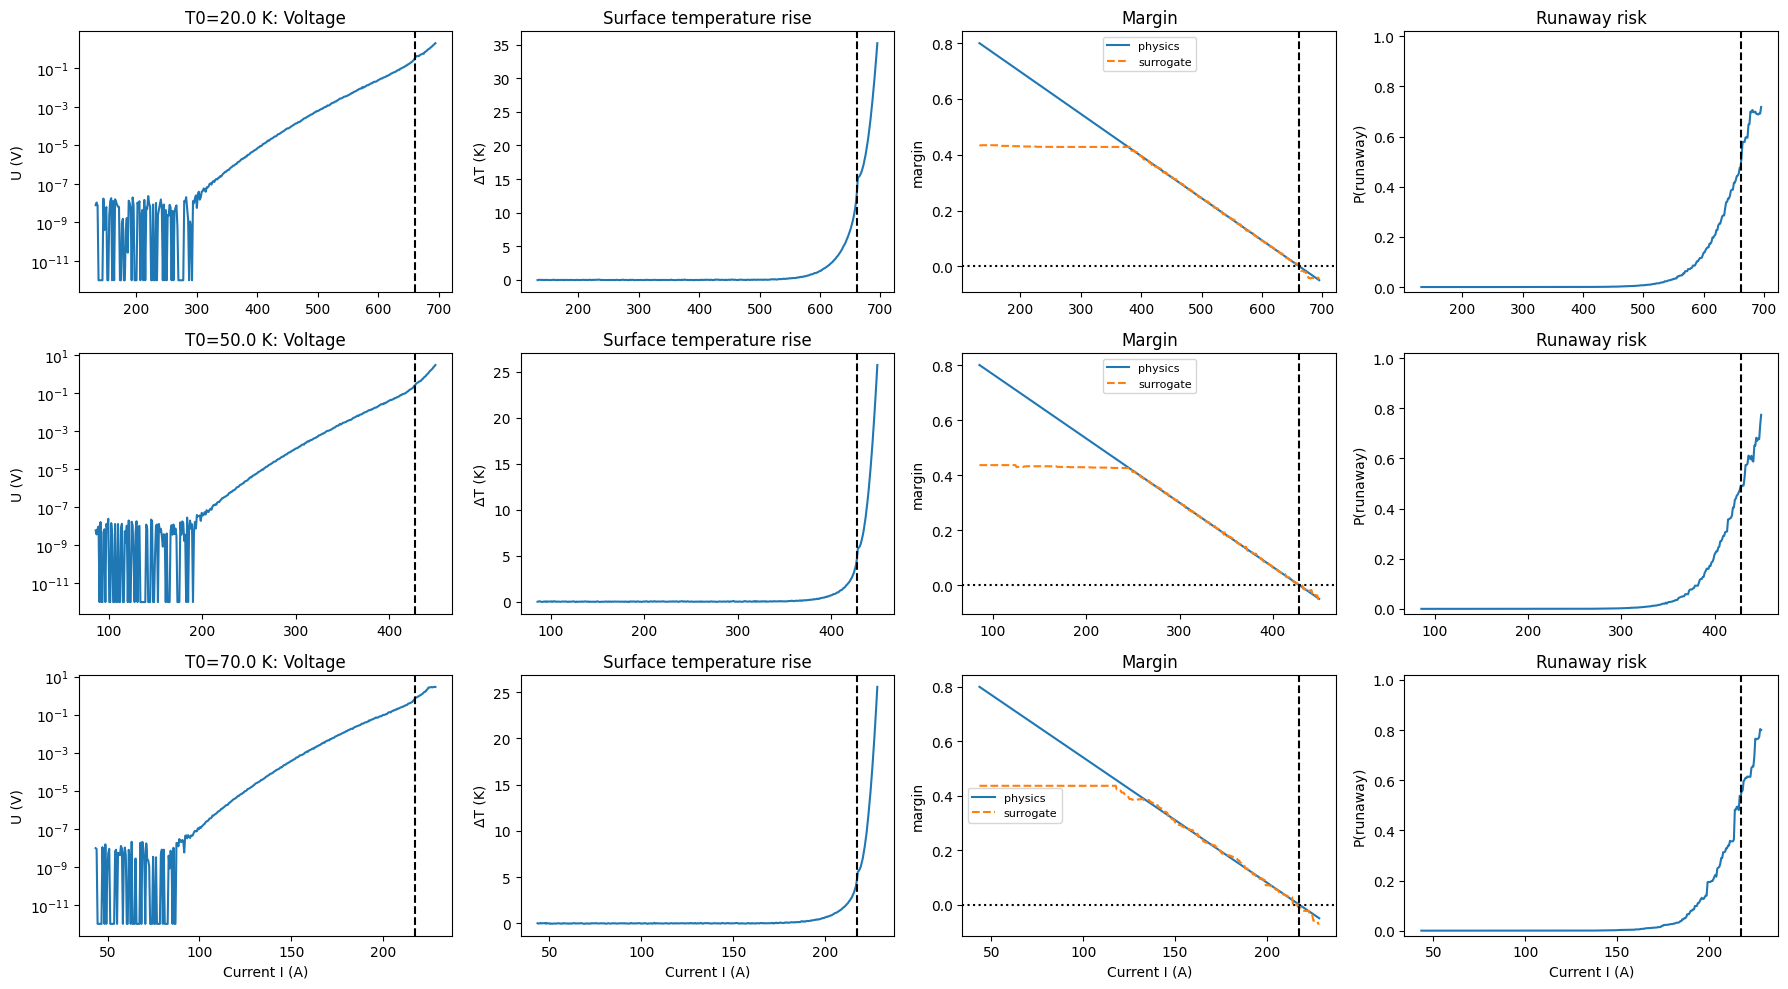

In [239]:
sample_T0s = [20.0, 50.0, 70.0]

fig, axes = plt.subplots(
    len(sample_T0s),
    4,
    figsize=(18, 10),
    sharex=False
)

for row, T0 in enumerate(sample_T0s):

    g = make_fast_branch_trace(
        T0=T0,
        seed=100 + row,
        n_steps=350,
        Imax_factor=1.05
    )

    if g.empty:
        print(f"Skipping T0={T0}: no valid ramp trace")
        continue

    Xg = g[telemetry_features].values

    g["pred_margin"] = margin_model.predict(Xg)
    g["pred_risk"] = expit(-g["pred_margin"] / 0.05)

    Istar = g["Istar_A"].iloc[0]

    axes[row,0].plot(g["I_A"], g["voltage_V"])
    axes[row,0].axvline(Istar, linestyle="--", color="k")
    axes[row,0].set_yscale("log")
    axes[row,0].set_ylabel("U (V)")
    axes[row,0].set_title(f"T0={T0:.1f} K: Voltage")

    axes[row,1].plot(g["I_A"], g["T_surface_K"] - g["T0_K"])
    axes[row,1].axvline(Istar, linestyle="--", color="k")
    axes[row,1].set_ylabel("ΔT (K)")
    axes[row,1].set_title("Surface temperature rise")

    axes[row,2].plot(g["I_A"], g["true_margin"], label="physics")
    axes[row,2].plot(g["I_A"], g["pred_margin"], "--", label="surrogate")
    axes[row,2].axvline(Istar, linestyle="--", color="k")
    axes[row,2].axhline(0, linestyle=":", color="k")
    axes[row,2].set_ylabel("margin")
    axes[row,2].set_title("Margin")
    axes[row,2].legend(fontsize=8)

    axes[row,3].plot(g["I_A"], g["pred_risk"])
    axes[row,3].axvline(Istar, linestyle="--", color="k")
    axes[row,3].set_ylim(-0.02, 1.02)
    axes[row,3].set_ylabel("P(runaway)")
    axes[row,3].set_title("Runaway risk")

for ax in axes[-1,:]:
    ax.set_xlabel("Current I (A)")

plt.tight_layout()
plt.show()